# Rigel - Beta Ori - 06/02/2026 - Line measures

In [1]:
import math
import random as rnd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.io import fits
from scipy.optimize import curve_fit
from scipy.special import voigt_profile

import warnings
warnings.filterwarnings('ignore')

## Initial configuration

In [2]:
SPECTRUM_FILE_NAME = "_rigel_20260206_770.fit"

##########################
# Continuum fitting related constants
##########################

EXCLUDED_REGIONS = [(3720,3725),(3730,3740),(3742,3755),(3762,3778),(3790,3810),(3815,3855),(3870,3910),(3940,4000),(4060,4140),(4300,4380),(4820,4900),(6450,6500),(6515,6600)]

SIGMALO_RANGE=(1.70, 2.20)
SIGMAHI_RANGE=(9.90,10.10)
DEGREE_RANGE = (6,12)

##########################
# Noise evaluation related constants
##########################

NOISE_EVALUATION_WINDOW = (6740,6810)
NOISE_CONTINUUM_WINDOW = (6600,7000)

NOISE_CONTINUUM_DEGREE = 10 # Degree of the polynomial used to fit the continuum in the noise evaluation window

##########################
# Line fitting related constants
##########################

GAUSS_FIT_WINDOW = 3 # in FWHM units
VOIGT_FIT_WINDOW = 3 # in FWHM units

GAUSSIAN_FIT_PLOT_WINDOW = 2.25    # In FWHM units
VOIGT_FIT_PLOT_WINDOW = 4.0        # In FWHM units

#############################
# Lines fit bounds
#############################

GAUSS_LAMBDA_WIN = 3.0  # In angstrom
VOIGT_LAMBDA_WIN = 3.0  # In angstrom

GAUSS_AMP_MIN = -1.5
GAUSS_AMP_MAX = 0.0

GAUSS_SIGMA_MIN = 0.5  # Respect to the expected value (for single lines) or sigma instr (for blended lines)
GAUSS_SIGMA_MAX = 4.0  # Respect to the expected value (for single lines) or sigma instr (for blended lines)

VOIGT_SIGMA_MIN = 0.5  # Respect to the expected value (for single lines) or sigma instr (for blended lines)
VOIGT_SIGMA_MAX = 4.0  # Respect to the expected value (for single lines) or sigma instr (for blended lines)

INSTR_RESOLUTION = 850    # R = lambda/delta_lambda

MONTECARLO_SAMPLES = 2500

ADD_NOISE = True

REMOVE_WORST_FITS = True
WORST_FIT_SIGMA_TO_REMOVE = 4
#WORST_FIT_PERC_TO_REMOVE = 50

SHOW_PARAM_DEPENDENCIES = False

## List of lines

In [3]:
measuring_lines = [{
    "name": "H beta",
    "model": "voigt",
    "central_wl": 4861.0,
    "winlo_range":(4550.0,4700.0),
    "winhi_range":(5150.0,5350.0)
    },
                   {
    "name": "H delta",
    "model": "voigt",
    "central_wl": 4101.0,
    "winlo_range":(3850.0,3950.0),
    "winhi_range":(4250.0,4350.0)
    },
                   {
    "name": "Si II 6347",
    "model": "gauss",
    "central_wl": 6347.0,
    "winlo_range":(6075.0,6200.0),
    "winhi_range":(6475.0,6600.0)
    },
                   {
    "name": "Si II 6371",
    "model": "gauss",
    "central_wl": 6371.0,
    "winlo_range":(6125.0,6250.0),
    "winhi_range":(6450.0,6575.0)
    },
                   {
    "name": "He I 4026",
    "model": "gauss",
    "central_wl": 4026.0,
    "winlo_range":(3800.0,3925.0),
    "winhi_range":(4100.0,4250.0)
    },
                   {
    "name": "He I 4388",
    "model": "gauss",
    "central_wl": 4388.0,
    "winlo_range":(4150.0,4300.0),
    "winhi_range":(4425.0,4550.0)
    },
                   {
    "name": "He I 4922",
    "model": "gauss",
    "central_wl": 4922.0,
    "winlo_range":(4650.0,4800.0),
    "winhi_range":(5000.0,5150.0)
    },
                   {
    "name": "He I 6678",
    "model": "gauss",
    "central_wl": 6678.0,
    "winlo_range":(6350.0,6630.0),
    "winhi_range":(6750.0,6875.0)
    }
]

In [4]:
measuring_blends = [{
    "name": "H gamma",
    "model": "voigt",
    "central_wls": [{"name": "H gamma",     "wavelength": 4341.0},
                    {"name": "Fe II 4352",  "wavelength": 4352.0}],
    "winlo_range":(4000.0,4225.0),
    "winhi_range":(4475.0,4600.0)
    },
                    {
    "name": "Mg II 4481",
    "model": "gauss",
    "central_wls": [{"name": "Mg II 4481", "wavelength": 4481.0},
                    {"name": "He I 4471",  "wavelength": 4470.0}],
    "winlo_range":(4100.0,4325.0),
    "winhi_range":(4575.0,4700.0)
    }
]

## Load spectrum

In [5]:
def load_spectrum(path):
    with fits.open(path) as hdul:
        hdr = hdul[0].header
        flux = hdul[0].data.astype(float)
        wl = hdr['CRVAL1'] + hdr['CDELT1'] * np.arange(hdr['NAXIS1'])
    good = flux > 0                      # drop the zeroed/bad pixels
    return wl[good], flux[good]

In [6]:
wl, flux = load_spectrum(SPECTRUM_FILE_NAME)

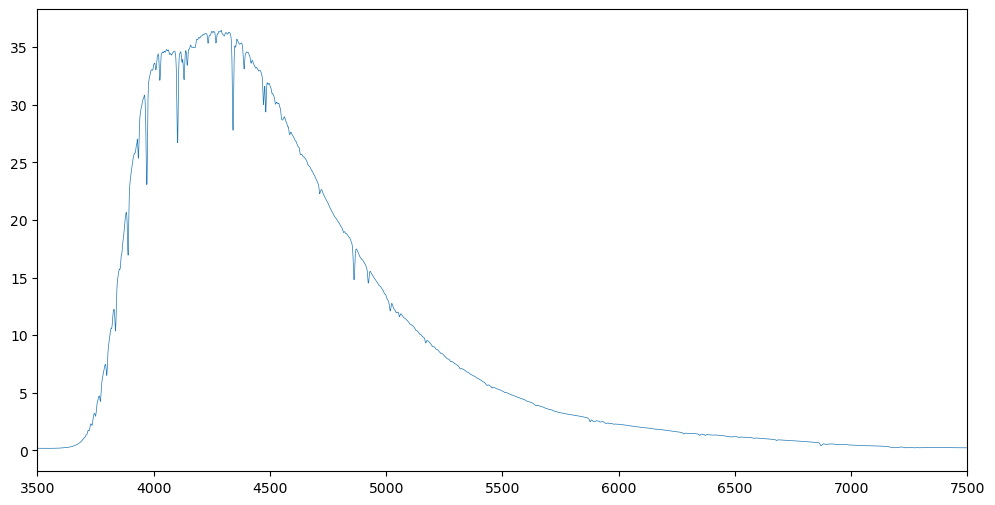

In [7]:
plt.figure(figsize=(12,6))
plt.plot(wl, flux, lw=0.5)
#plt.ylim(ymin, ymax)
plt.xlim(3500,7500)
plt.show()

## Continuum related procedures

In [8]:
def robust_continuum_fit(x, y, exclude_windows, degree, sigma_lo=3.0, sigma_hi=3.0, max_iter=20):
    seed = np.ones(len(x), dtype=bool)
    for lo, hi in exclude_windows:
        seed &= ~((x >= lo) & (x <= hi))
    xc = x - x.mean()
    mask = seed.copy()
    for i in range(max_iter):
        p = np.polyfit(xc[mask], y[mask], degree)
        resid = y - np.polyval(p, xc)
        s = resid[mask].std()
        new_mask = seed & (resid > -sigma_lo * s) & (resid < sigma_hi * s)
        if np.array_equal(new_mask, mask):
            break
        mask = new_mask
    return p, x.mean(), mask

In [9]:
def rectify_zone(wl, flux, zone, plot=False, degree=7, max_iter=20, sigma_lo=1.5, sigma_hi=10.0):
    zone_min, zone_max = zone
    enlarged_zone_min = zone_min - 50
    enlarged_zone_max = zone_max + 50

    mw = (wl >= enlarged_zone_min) & (wl <= enlarged_zone_max)
    p, wlmean, mask = robust_continuum_fit(wl[mw], flux[mw], EXCLUDED_REGIONS, degree, max_iter=max_iter, sigma_lo=sigma_lo, sigma_hi=sigma_hi)
    cont = np.polyval(p, wl - wlmean)[mw]

    if plot:
        plt.figure(figsize=(12,6))
        plt.plot(wl[mw], flux[mw], lw=0.5)
        plt.plot(wl[mw], cont, lw=0.5)
        #plt.ylim(ymin, ymax)
        plt.xlim(enlarged_zone_min,enlarged_zone_max)
        plt.title("Continuum fit")
        plt.show()    

    rect3 = flux[mw] / cont
    wl3 = wl[mw]
    mw = (wl3 >= zone_min) & (wl3 <= zone_max)
    rect3 = rect3[mw]
    wl3 = wl3[mw]  

    if plot:
        plt.figure(figsize=(12,6))
        plt.plot(wl3, rect3, lw=0.5)
        #plt.ylim(0.7, 1.05)
        plt.xlim(enlarged_zone_min,enlarged_zone_max)
        plt.title("Continuum calibrated spectrum")
        plt.show()

    return wl3, rect3

## Noise evaluation

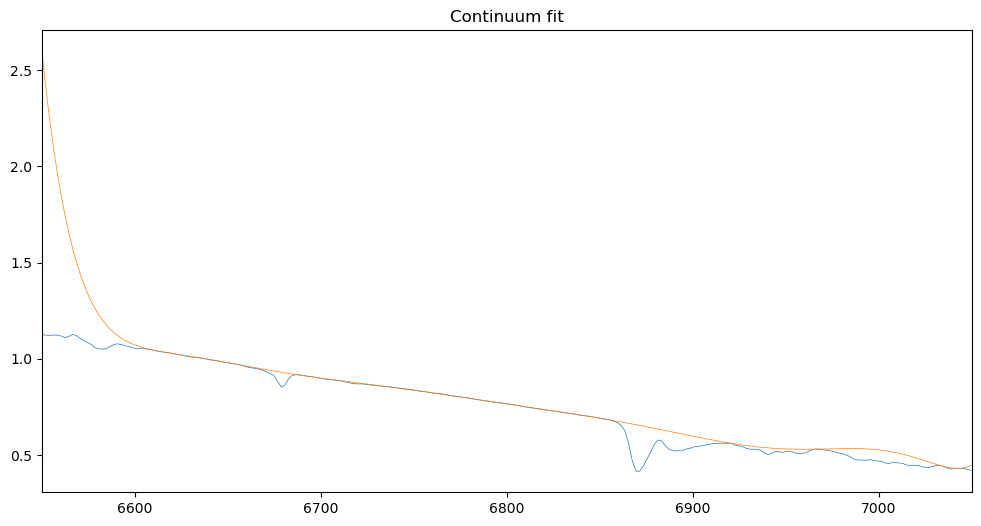

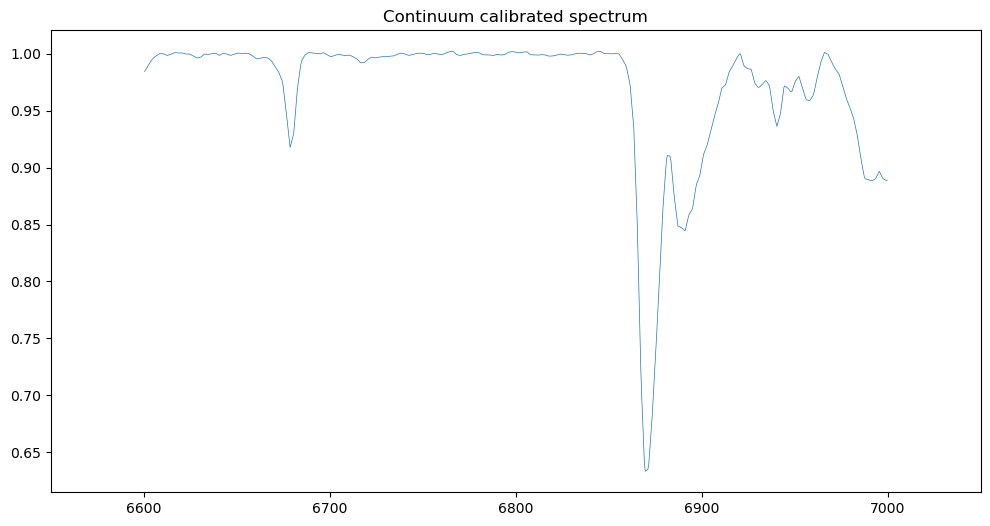

Noise =  0.001131206164552792 Flux at eval window =  0.8019137382507324 SNR =  708.9014923886654


In [10]:
continuum_mask = (wl > NOISE_CONTINUUM_WINDOW[0]) & (wl < NOISE_CONTINUUM_WINDOW[1])
wlzone, rectzone = rectify_zone(wl, flux, NOISE_CONTINUUM_WINDOW, degree=NOISE_CONTINUUM_DEGREE, plot=True)
evaluation_mask = (wlzone > NOISE_EVALUATION_WINDOW[0]) & (wlzone < NOISE_EVALUATION_WINDOW[1])
noise = 1.4826 * np.median(
        np.abs(rectzone[evaluation_mask] - np.median(rectzone[evaluation_mask]))
    )
noise_evaluation_flux = np.median(flux[continuum_mask][evaluation_mask])
snr = noise_evaluation_flux / noise
print("Noise = ",noise, "Flux at eval window = ", noise_evaluation_flux, "SNR = ", snr)

## Line Fitting procedures

In [11]:
def gaussian_model(x, amp, mu, sigma, offset):
    return amp * np.exp(-0.5 * ((x - mu) / sigma) ** 2) + offset
    
    

def voigt_model(x, amp, mean, sigma, gamma, offset):
    # voigt_profile(x - mean, sigma, gamma) è normalizzata a area = 1
    return amp * voigt_profile(x - mean, sigma, gamma) + offset

In [12]:
def plot_gauss_fit(w, f, popt, name):
    plt.figure(figsize=(6,4))
    plt.plot(w, f, "k", label="Data")
    plt.plot(w, gaussian_model(w, *popt), "r", label="Gaussian fit")
    plt.legend()
    plt.xlabel("Wavelength")
    plt.title(name)
    plt.show()

In [13]:
def calc_gaussian_chi2(w, f, amp, mu, sigma, offset, fwhm):
    wl_min = mu - fwhm
    wl_max = mu + fwhm
    mask = (w > wl_min) & (w < wl_max)
    res_w = w[mask]
    res_f = f[mask]
    return (((res_f - gaussian_model(res_w, amp, mu, sigma, offset)) ** 2)/gaussian_model(res_w, amp, mu, sigma, offset)).sum()

In [14]:
def fit_line_gaussian(wavelength, flux, lam_expected, fwhm_expected, plot=False, name=""):    
    peak_idx = np.argmin(np.abs(wavelength - lam_expected))
    amp0 = max(1.0 - flux[peak_idx], 0.0)
    offset = 1.0
    #p0 = [-amp0, lam_expected, fwhm_expected / 2.355, median_continuum]
    p0 = [-amp0, lam_expected, fwhm_expected / 2.355]
    #if plot:
    #    print("initial guess", p0)
    fit_wl_min = lam_expected - GAUSS_FIT_WINDOW * fwhm_expected
    fit_wl_max = lam_expected + GAUSS_FIT_WINDOW * fwhm_expected
    fit_window_mask = (wavelength > fit_wl_min) & (wavelength < fit_wl_max) 
    w = wavelength[fit_window_mask]
    f = flux[fit_window_mask]
    try:
        # popt, _ = curve_fit(gaussian_model, w, f, p0=p0)
        bounds_lo = [GAUSS_AMP_MIN * amp0, lam_expected - GAUSS_LAMBDA_WIN, GAUSS_SIGMA_MIN * fwhm_expected / 2.355]
        bounds_hi = [GAUSS_AMP_MAX * amp0, lam_expected + GAUSS_LAMBDA_WIN, GAUSS_SIGMA_MAX * fwhm_expected / 2.355]
        popt, _ = curve_fit(
            lambda x, a, m, s: gaussian_model(x, a, m, s, offset),
            w,
            f,
            p0 = p0,
            bounds = (bounds_lo, bounds_hi))
        #amp, mu, sigma, offset = popt
        amp, mu, sigma = popt
            
        sigma_nom = abs(sigma)
        fwhm_fit = 2.355 * sigma_nom
        fwhm_nom = fwhm_fit #np.clip(fwhm_fit, 0.7 * fwhm_instr, 1.5 * fwhm_instr)
        ew_nom = np.sqrt(2 * np.pi) * abs(amp) * sigma_nom / offset

        chi2 = calc_gaussian_chi2(w, f, amp, mu, sigma, offset, fwhm_nom)
        
        if plot:
            print("amp =",amp,"\nmu =",mu,"\nsigma =",sigma,"\noffset =",offset,"\nchi2 = ",chi2)
            plot_mask = (w >= mu-GAUSSIAN_FIT_PLOT_WINDOW*fwhm_nom) & (w <= mu+GAUSSIAN_FIT_PLOT_WINDOW*fwhm_nom)
            plot_gauss_fit(w[plot_mask], f[plot_mask], (amp, mu, sigma, offset), name)
    except RuntimeError:
        fwhm_nom = np.nan
        ew_nom = np.nan
        mu = np.nan
        amp = np.nan
        chi2 = np.nan

    return (mu, ew_nom, fwhm_nom, amp, chi2)

In [15]:
def plot_voigt_fit(w, f, popt, name):
    plt.figure(figsize=(6,4))
    plt.plot(w, f, "k", label="Data")
    plt.plot(w, voigt_model(w, *popt), "r", label="Voigt fit")
    plt.legend()
    plt.xlabel("Wavelength")
    plt.title(name)
    plt.show()

In [16]:
def calc_voigt_chi2(w, f, amp, mu, sigma, gam, offset, fwhm):
    wl_min = mu - 2 * fwhm
    wl_max = mu + 2 * fwhm
    mask = (w > wl_min) & (w < wl_max)
    res_w = w[mask]
    res_f = f[mask]
    return (((res_f - voigt_model(res_w, amp, mu, sigma, gam, offset))**2)/voigt_model(res_w, amp, mu, sigma, gam, offset)).sum()

In [17]:
def fit_line_voigt(wavelength, flux, lam_expected, fwhm_expected, plot=False, name=""):
    
    peak_idx = np.argmin(np.abs(wavelength - lam_expected))
    amp0 = max(1.0 - flux[peak_idx], 0.0)
    offset = 1.0
    p0 = [-amp0, lam_expected, fwhm_expected / 2.355, fwhm_expected / 2.355]
    #p0 = [-amp0, lam_expected, fwhm_expected / 2.355, fwhm_expected / 2.355, offset]
    fit_wl_min = lam_expected - VOIGT_FIT_WINDOW * fwhm_expected
    fit_wl_max = lam_expected + VOIGT_FIT_WINDOW * fwhm_expected
    fit_window_mask = (wavelength > fit_wl_min) & (wavelength < fit_wl_max) 
    w = wavelength[fit_window_mask]
    f = flux[fit_window_mask]
    #if plot:
    #    print("initial guess", p0)
    try:
        #popt, _ = curve_fit(voigt_model, w, f, p0=p0)
        popt, _ = curve_fit(
            lambda x, a, m, s, g: voigt_model(x, a, m, s, g, offset),
            w,
            f,
            p0 = p0)
        #amp, mu, sigma, gam, offset = popt
        amp, mu, sigma, gam = popt
        #sigma_nom = abs(sigma)

        intensity = amp * voigt_profile(0.0, sigma, gam)
        
        f_g = 2 * sigma * np.sqrt(2 * np.log(2))
        f_l = 2 * gam
        fwhm_nom = 0.5346 * f_l + np.sqrt(0.2166 * f_l**2 + f_g**2)
        
        ew_nom = abs(amp)/offset

        chi2 = calc_voigt_chi2(w, f, amp, mu, sigma, gam, offset, fwhm_nom)
        
        if plot:
            print("amp =",amp,"\nmu =",mu,"\nsigma =",sigma,"\ngamma =",gam,"\noffset =",offset,"\nchi2 =",chi2)
            plot_mask = (w >= mu-VOIGT_FIT_PLOT_WINDOW*fwhm_nom) & (w <= mu+VOIGT_FIT_PLOT_WINDOW*fwhm_nom)
            plot_voigt_fit(w[plot_mask], f[plot_mask], (amp, mu, sigma, gam, offset), name)
    except RuntimeError:
        fwhm_nom = np.nan
        ew_nom = np.nan
        mu = np.nan
        intensity = np.nan
        chi2 = np.nan

    return (mu, ew_nom, fwhm_nom, intensity, chi2)

In [18]:
# Number of fit parameters used by each component model:
#   gauss : amp (line depth), mu, sigma
#   voigt : amp (area),       mu, sigma, gamma
PARAMS_PER_MODEL = {"gauss": 3, "voigt": 4}


def normalize_model_name(line):
    """Return 'gauss' or 'voigt' for a blend component dict (default: 'gauss')."""
    model = str(line.get("model", "gauss")).strip().lower()
    if model in ("gauss", "gaussian"):
        return "gauss"
    if model == "voigt":
        return "voigt"
    raise ValueError(f"Unknown model '{line.get('model')}' for blend component "
                     f"'{line.get('name')}': use 'gauss' or 'voigt'")


def voigt_fwhm(sigma, gamma):
    # Olivero & Longbothum approximation (same formula used by fit_line_voigt)
    f_g = 2 * sigma * np.sqrt(2 * np.log(2))
    f_l = 2 * gamma
    return 0.5346 * f_l + np.sqrt(0.2166 * f_l**2 + f_g**2)


def component_profile(x, model, params):
    """Profile of a single blend component, WITHOUT the continuum offset."""
    if model == "voigt":
        amp, mu, sigma, gamma = params
        return amp * voigt_profile(x - mu, sigma, gamma)
    amp, mu, sigma = params
    return amp * np.exp(-0.5 * ((x - mu) / sigma) ** 2)


def split_blend_params(models, params):
    """Split the flat parameter vector into one tuple per component."""
    result = []
    k = 0
    for model in models:
        n = PARAMS_PER_MODEL[model]
        result.append(tuple(params[k:k + n]))
        k += n
    return result


def multi_line_model(x, offset, models, *params):
    """Sum of gaussian / voigt components (one entry of `models` per component) + continuum."""
    model = np.zeros_like(x, dtype=float)
    for m, p in zip(models, split_blend_params(models, params)):
        model += component_profile(x, m, p)
    return model + offset

In [19]:
def multi_line_initial_guess(lines, wavelength, flux):
    """Initial guess and bounds for a blend of gaussian / voigt components.

    `lines` is the list of component dicts ("wavelength" and optionally "model").
    """
    p0 = []
    bounds_lo = []
    bounds_hi = []
    for line in lines:
        model = normalize_model_name(line)
        lam0 = line["wavelength"]
        peak_index = np.argmin(np.abs(wavelength - lam0))
        depth0 = min(flux[peak_index] - 1.0, 0.0)
        fwhm_instr = lam0 / INSTR_RESOLUTION
        sigma_instr = fwhm_instr / 2.355

        if model == "gauss":
            p0 += [depth0, lam0, sigma_instr]
            bounds_lo += [GAUSS_AMP_MIN, lam0 - GAUSS_LAMBDA_WIN, GAUSS_SIGMA_MIN * sigma_instr]
            bounds_hi += [GAUSS_AMP_MAX, lam0 + GAUSS_LAMBDA_WIN, GAUSS_SIGMA_MAX * sigma_instr]
        else:
            # Voigt amplitude is the (normalised) area, i.e. -EW for a continuum of 1.
            # Convert the observed depth to an area using the starting profile shape.
            gamma0 = 0.5 * sigma_instr
            amp0 = depth0 / voigt_profile(0.0, sigma_instr, gamma0)
            # Same limits as the gaussian, expressed as areas (depth * width)
            area_scale = np.sqrt(2 * np.pi) * 4.0 * sigma_instr
            amp_lo, amp_hi = -1.5 * area_scale, 0.5 * area_scale
            p0 += [float(np.clip(amp0, amp_lo, amp_hi)), lam0, sigma_instr, gamma0]
            bounds_lo += [amp_lo, lam0 - VOIGT_LAMBDA_WIN, VOIGT_SIGMA_MIN * sigma_instr, 0.0]
            bounds_hi += [amp_hi, lam0 + VOIGT_LAMBDA_WIN, VOIGT_SIGMA_MAX * sigma_instr, 4.0 * sigma_instr]

    return (p0, bounds_lo, bounds_hi)

In [20]:
def plot_multi_line_fit(w, f, popt, models, component, name):
    """Plot data, total blend fit and the component called `name`.

    `component` is the (model, params) pair of the component to highlight.
    """
    comp_model, comp_params = component
    plt.figure(figsize=(6,4))
    plt.plot(w, f, "k", label="Data")
    plt.plot(w, multi_line_model(w, 1.0, models, *popt), "r", label="Blend fit")
    plt.plot(w, component_profile(w, comp_model, comp_params) + 1.0, "y",
             label=f"{name} ({comp_model})")
    plt.legend()
    plt.xlabel("Wavelength")
    plt.title(name)
    plt.show()

In [21]:
def fit_blend_group(wavelength, flux, lines, plot=False):
    lams_expected = [l.get("wavelength") for l in lines]
    models = [normalize_model_name(l) for l in lines]
    wl_lam_min = min(lams_expected)
    wl_lam_max = max(lams_expected)
    wl_min = wl_lam_min - 2.5*(wl_lam_max - wl_lam_min)/2.0
    wl_max = wl_lam_max + 2.5*(wl_lam_max - wl_lam_min)/2.0
    
    mask = (wavelength > wl_min) & (wavelength < wl_max)
    
    w = wavelength[mask]
    f = flux[mask]
    offset = 1.0
    
    p0, bounds_lo, bounds_hi = multi_line_initial_guess(lines, w, f)
    
    popt, _ = curve_fit(
            lambda x, *params: multi_line_model(x, offset, models, *params),
            w,
            f,
            p0 = p0,
            bounds = (bounds_lo, bounds_hi))
    
    # One parameter tuple per component (3 values for gauss, 4 for voigt)
    component_results = split_blend_params(models, popt)

    chi2 = (((multi_line_model(w, offset, models, *popt) - f) ** 2)/multi_line_model(w, offset, models, *popt)).sum()
    
    final_results = []
    
    for line, model, params in zip(lines, models, component_results):
        if model == "voigt":
            amp, mu, sigma, gam = params
            fwhm_nom = voigt_fwhm(sigma, gam)
            ew_nom = abs(amp) / offset
            intensity = amp * voigt_profile(0.0, sigma, gam)
        else:
            amp, mu, sigma = params
            fwhm_nom = 2.355 * abs(sigma)
            ew_nom = np.sqrt(2 * np.pi) * abs(amp) * abs(sigma) / offset
            intensity = amp
        
        final_results.append((line["name"], mu, ew_nom, fwhm_nom, intensity, chi2))
        
        if plot:
            print(line["name"], f"({model})")
            if model == "voigt":
                print("amp =",amp,"\nmu =",mu,"\nsigma =",sigma,"\ngamma =",gam,"\noffset =",offset,"\nchi2 =",chi2)
            else:
                print("amp =",amp,"\nmu =",mu,"\nsigma =",sigma,"\noffset =",offset,"\nchi2 =",chi2)
            plot_multi_line_fit(w, f, popt, models, (model, params), line["name"])
        
    return final_results

## Functions for error on continuum placement

In [22]:
def fit_varying_continuum(wl, flux, model, expected_lam, expected_width, add_noise=False, noise=0.0, noise_evaluation_flux=1.0, sigma_lo_range=(1.5,2.0), sigma_hi_range=(9.9,10.1), degree_range=(6,14), maxiter_range=(10,30), winlo_range=None, winhi_range=None):
    results = pd.DataFrame(columns=("sigma_lo","sigma_hi","degree","maxiter","win_lo","win_hi","wavelength","ew","fwhm","intensity","chi2"))
    for i in range(1,MONTECARLO_SAMPLES):
        try:
            sigma_lo = rnd.uniform(*sigma_lo_range)
            sigma_hi = rnd.uniform(*sigma_hi_range)
            degree = rnd.randrange(*degree_range)
            maxiter = rnd.randrange(*maxiter_range)
            win = (rnd.uniform(*winlo_range), rnd.uniform(*winhi_range))
            if add_noise:
                win_mask = (wl > win[0]) & (wl < win[1])
                rescaled_noise = noise * np.sqrt(np.median(flux[win_mask])*noise_evaluation_flux)
                noised_flux = (flux + np.random.normal(0, rescaled_noise, size=len(flux)))
                wlzone, rectzone = rectify_zone(wl, noised_flux, win, plot=False, sigma_lo=sigma_lo, sigma_hi=sigma_hi, degree=degree, max_iter=maxiter)
            else:
                wlzone, rectzone = rectify_zone(wl, flux, win, plot=False, sigma_lo=sigma_lo, sigma_hi=sigma_hi, degree=degree, max_iter=maxiter)
            if (model == "voigt"):
                lam, ew, fwhm, amp, chi2 = fit_line_voigt(wlzone, rectzone, expected_lam, expected_width, plot=False)
            else:
                lam, ew, fwhm, amp, chi2 = fit_line_gaussian(wlzone, rectzone, expected_lam, expected_width, plot=False)
            results.loc[i] = pd.Series({"sigma_lo":sigma_lo, "sigma_hi":sigma_hi, "degree":degree, "maxiter":maxiter, "win_lo":win[0], "win_hi":win[1], "wavelength":lam, "ew":ew, "fwhm":fwhm, "intensity":amp, "chi2": chi2})
        except Exception as e:
            print(e)

    if REMOVE_WORST_FITS:
        for i in range(1,20):
            m_res = results["chi2"].mean()
            s_res = results["chi2"].std()
            results = results[(results["chi2"]-m_res).abs() <= WORST_FIT_SIGMA_TO_REMOVE*s_res]
        #chi2_cutoff = results["chi2"].quantile(1.0 - WORST_FIT_PERC_TO_REMOVE/100.0)
        #results = results[results["chi2"] <= chi2_cutoff]

    m = results["ew"].mean()
    results["ew_dist"] = abs(results["ew"] - m)
    
    return results

In [23]:
def refit_with_best(column, results, wl, flux, model, expected_lam, expected_width, plot=False, name=""):
    sort_col = column + "_dist"
    sorted_results = results.sort_values(by=[sort_col], ascending=True)
    best = sorted_results.iloc[0]
    sigma_lo = best["sigma_lo"]
    sigma_hi = best["sigma_hi"]
    degree = best["degree"]
    maxiter = best["maxiter"].astype(int)
    win = (best["win_lo"], best["win_hi"])
    wlzone, rectzone = rectify_zone(wl, flux, win, plot=plot, sigma_lo=sigma_lo, sigma_hi=sigma_hi, degree=degree, max_iter=maxiter)
    if (model == "voigt"):
        lam, ew, fwhm, amp, chi2 = fit_line_voigt(wlzone, rectzone, expected_lam, expected_width, plot=plot, name=name)
    else:
        lam, ew, fwhm, amp, chi2 = fit_line_gaussian(wlzone, rectzone, expected_lam, expected_width, plot=plot, name=name)
    return (lam, ew, fwhm, amp)

In [24]:
def fit_blend_varying_continuum(wl, flux, blended_lines, add_noise=False, noise=0.0, noise_evaluation_flux=1.0, sigma_lo_range=(1.5,2.0), sigma_hi_range=(9.9,10.1), degree_range=(6,14), maxiter_range=(10,30), winlo_range=None, winhi_range=None):
    results = pd.DataFrame(columns=("sigma_lo","sigma_hi","degree","maxiter","win_lo","win_hi","record","line","wavelength","ew","fwhm","intensity","chi2"))
    j = 0
    for i in range(1,MONTECARLO_SAMPLES):
        try:
            sigma_lo = rnd.uniform(*sigma_lo_range)
            sigma_hi = rnd.uniform(*sigma_hi_range)
            degree = rnd.randrange(*degree_range)
            maxiter = rnd.randrange(*maxiter_range)
            win = (rnd.uniform(*winlo_range), rnd.uniform(*winhi_range))
            if add_noise:
                win_mask = (wl > win[0]) & (wl < win[1])
                rescaled_noise = noise * np.sqrt(np.median(flux[win_mask])*noise_evaluation_flux)
                noised_flux = (flux + np.random.normal(0, rescaled_noise, size=len(flux)))
                wlzone, rectzone = rectify_zone(wl, noised_flux, win, plot=False, sigma_lo=sigma_lo, sigma_hi=sigma_hi, degree=degree, max_iter=maxiter)
            else:
                wlzone, rectzone = rectify_zone(wl, flux, win, plot=False, sigma_lo=sigma_lo, sigma_hi=sigma_hi, degree=degree, max_iter=maxiter)
            blend_results = fit_blend_group(wlzone, rectzone, blended_lines, plot=False)
            for line_result in blend_results:
                name, lam_detected, ew, fwhm, amp, chi2 = line_result
                results.loc[j] = pd.Series({"sigma_lo":sigma_lo, "sigma_hi":sigma_hi, "degree":degree, "maxiter":maxiter, "win_lo":win[0], "win_hi":win[1], "record":i, "line":name, "wavelength":lam_detected, "ew":ew, "fwhm":fwhm, "intensity":amp, "chi2": chi2})            
                j = j + 1
        except Exception as e:
            print(e)

    results["ew_dist"] = (results["ew"] - results.groupby("line")["ew"].transform("mean")).abs()
    results["ew_dist_ssq"] = (results["ew_dist"]**2).groupby(results["record"]).transform("sum")

    if REMOVE_WORST_FITS:
        #for i in range(1,20):
        #    s = results["ew_dist_ssq"].std()
        #    results = results[results["ew_dist_ssq"] <= 10*s]
        for i in range(1,20):
            m_res = results["chi2"].mean()
            s_res = results["chi2"].std()
            results = results[(results["chi2"]-m_res).abs() <= WORST_FIT_SIGMA_TO_REMOVE*s_res]
        #chi2_cutoff = results["chi2"].quantile(1.0 - WORST_FIT_PERC_TO_REMOVE/100.0)
        #results = results[results["chi2"] <= chi2_cutoff]
    
    return results

In [25]:
def refit_blend_with_best(column, results, wl, flux, blended_lines, expected_width, plot=False, name=""):
    sort_col = column + "_dist_ssq"
    sorted_results = results.sort_values(by=[sort_col], ascending=True)
    best = sorted_results.iloc[0]
    sigma_lo = best["sigma_lo"]
    sigma_hi = best["sigma_hi"]
    degree = best["degree"]
    maxiter = best["maxiter"]
    win = (best["win_lo"], best["win_hi"])
    wlzone, rectzone = rectify_zone(wl, flux, win, plot=True, sigma_lo=sigma_lo, sigma_hi=sigma_hi, degree=degree, max_iter=maxiter)
    blend_results = fit_blend_group(wlzone, rectzone, blended_lines, plot=True)

## Complete measure procedures

In [26]:
def round_measurement(value, error):
    exponent = math.floor(math.log10(error))
    first_digit = int(error / (10 ** exponent))

    sig_figs = 2 if first_digit in (1,2) else 1

    decimals = sig_figs - exponent - 1

    value_rounded = round (value, decimals)
    error_rounded = round(error, decimals)

    return value_rounded, error_rounded

In [27]:
from IPython.display import Markdown
from IPython.display import display

def measure_line(wl, flux, measuring_line, show_param_dependencies=False):
    name = measuring_line["name"]
    
    display(Markdown(f"### Measuring {name}"))
    model = measuring_line["model"]
    central_wl = measuring_line["central_wl"]
    winlo_range = measuring_line["winlo_range"]
    winhi_range = measuring_line["winhi_range"]
    
    display(Markdown(f"#### {name} preliminary fit"))
    rect_win = (winlo_range[1], winhi_range[0])
    wlzone, rectzone = rectify_zone(wl, flux, rect_win, plot=True)
    if model == "voigt":
        lam, ew, fwhm, amp, chi2 = fit_line_voigt(wlzone, rectzone, central_wl, 5.0, plot=True, name=name)
    else:
        lam, ew, fwhm, amp, chi2 = fit_line_gaussian(wlzone, rectzone, central_wl, 5.0, plot=True, name=name)
    print("Lambda = ", lam, "Eq Width =", ew, "FWHM = ", fwhm, "Intensity = ", amp)
    
    display(Markdown(f"#### {name} optimization"))
    results = fit_varying_continuum(wl, flux, model, central_wl, fwhm, winlo_range=winlo_range, winhi_range=winhi_range, degree_range=DEGREE_RANGE, sigma_lo_range=SIGMALO_RANGE, sigma_hi_range=SIGMAHI_RANGE, add_noise=ADD_NOISE, noise=noise, noise_evaluation_flux=noise_evaluation_flux)

    fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12,6))
    plt.subplots_adjust(wspace=0.5, hspace=0.5)
    
    m_ew = results["ew"].mean()
    s_ew = results["ew"].std()
    results.plot.hist(column=["ew"], title="EW mean=%g std dev=%g" % round_measurement(m_ew,s_ew), ax=axes[0,0])
    
    m_fwhm = results["fwhm"].mean()
    s_fwhm = results["fwhm"].std()
    results.plot.hist(column=["fwhm"], title="FWHM mean=%g std dev=%g" % round_measurement(m_fwhm,s_fwhm), ax=axes[0,1])
    
    m_wl = results["wavelength"].mean()
    s_wl = results["wavelength"].std()
    results.plot.hist(column=["wavelength"], title="Central wavelength mean=%g std dev=%g" % round_measurement(m_wl,s_wl), ax=axes[1,0])
    
    m_amp = results["intensity"].mean()
    s_amp = results["intensity"].std()
    results.plot.hist(column=["intensity"], title="Intensity mean=%g std dev=%g" % round_measurement(m_amp,s_amp), ax=axes[1,1])
    
    plt.show()

    display(Markdown(f"#### {name} re-fit with best parameters"))
    lam, ew, fwhm, amp = refit_with_best("ew", results, wl, flux, model, central_wl, m_fwhm, plot=True, name=name)
    print("Lambda = ", lam, "Eq Width =", ew, "FWHM = ", fwhm, "Intensity = ", amp)

    if show_param_dependencies:
        display(Markdown(f"#### {name} continuum parameters dependencies"))
        results["win_size"] = results["win_hi"] - results["win_lo"]
        results["dist"] = abs(results["ew"] - m_ew)

        results.plot.hist(column=["chi2"], figsize=(12,6), title="Chi quadro")
        
        sorted_results = results.sort_values(by=["dist"], ascending=True)
        sorted_results.plot(x="dist", y="sigma_lo", ylim=(0,6))
        sorted_results.plot(x="dist", y="degree", ylim=(2,15))
        sorted_results.plot(x="dist", y="maxiter", ylim=(8,32))
        sorted_results.plot(x="dist", y="win_size", ylim=(400,800))
        
        results.sort_values(by=["sigma_lo"], ascending=True).plot(x="sigma_lo", y="dist", ylim=(0,8))
        results.sort_values(by=["win_size"], ascending=True).plot(x="win_size", y="dist", ylim=(0,8))
        
        sorted_results.plot.scatter(x="degree", y="win_size", c="dist")
        sorted_results.plot.scatter(x="win_lo", y="win_hi", c="dist")
        plt.show()
    
    return pd.Series({"line_name":name, "wavelength":m_wl, "delta_wavelength":s_wl, "ew":m_ew, "delta_ew":s_ew, "fwhm":m_fwhm, "delta_fwhm":s_fwhm, "intensity": m_amp, "delta_intensity": s_amp})

In [28]:
def measure_blend(wl, flux, measuring_blend, show_param_dependencies=False):
    name = measuring_blend["name"]
    
    display(Markdown(f"### Measuring {name}"))
    blended_lines = measuring_blend["central_wls"]
    winlo_range = measuring_blend["winlo_range"]
    winhi_range = measuring_blend["winhi_range"]
    print("Blended lines=", blended_lines)
    display(Markdown(f"#### {name} preliminary fit"))
    rect_win = (winlo_range[1], winhi_range[0])
    wlzone, rectzone = rectify_zone(wl, flux, rect_win, plot=True)
    fit_blend_group(wlzone, rectzone, blended_lines, plot=True)
    
    display(Markdown(f"#### {name} optimization"))
    results = fit_blend_varying_continuum(wl, flux, blended_lines, degree_range=DEGREE_RANGE, sigma_lo_range=SIGMALO_RANGE, sigma_hi_range=SIGMAHI_RANGE, add_noise=ADD_NOISE, noise=noise, noise_evaluation_flux=noise_evaluation_flux, winlo_range=winlo_range, winhi_range=winhi_range)

    blend_results = pd.DataFrame(columns=("line_name","wavelength","delta_wavelength","ew","delta_ew","fwhm","delta_fwhm","intensity","delta_intensity"))
    i = 0
    for line in blended_lines:
        line_name = line["name"]
        display(Markdown(f"#### Plotting results for {line_name}"))
        line_results = results[results["line"] == line["name"]]

        fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12,6))
        plt.subplots_adjust(wspace=0.5, hspace=0.5)
        
        m_ew = line_results["ew"].mean()
        s_ew = line_results["ew"].std()
        line_results.plot.hist(column=["ew"], figsize=(12,6), title="EW mean=%g std dev=%g" % round_measurement(m_ew,s_ew), ax=axes[0,0])
    
        m_fwhm = line_results["fwhm"].mean()
        s_fwhm = line_results["fwhm"].std()
        line_results.plot.hist(column=["fwhm"], figsize=(12,6), title="FWHM mean=%g std dev=%g" % round_measurement(m_fwhm,s_fwhm), ax=axes[0,1])
        
        m_wl = line_results["wavelength"].mean()
        s_wl = line_results["wavelength"].std()
        line_results.plot.hist(column=["wavelength"], figsize=(12,6), title="Central wavelength mean=%g std dev=%g" % round_measurement(m_wl,s_wl), ax=axes[1,0])

        m_amp = line_results["intensity"].mean()
        s_amp = line_results["intensity"].std()
        line_results.plot.hist(column=["intensity"], figsize=(12,6), title="Intensity mean=%g std dev=%g" % round_measurement(m_amp,s_amp), ax=axes[1,1])
        plt.show()
    
        # print("Mean:", m_ew)
        # print("Std Dev:",s_ew)

        line_results = pd.Series({"line_name":line_name, "wavelength":m_wl, "delta_wavelength":s_wl, "ew":m_ew, "delta_ew":s_ew, "fwhm":m_fwhm, "delta_fwhm":s_fwhm, "intensity":m_amp, "delta_intensity":s_amp})
        blend_results.loc[i] = line_results
        i = i + 1

    display(Markdown(f"#### {name} re-fit with best parameters"))
    refit_blend_with_best("ew", results, wl, flux, blended_lines, m_fwhm, plot=True, name=name)

    if show_param_dependencies:
        display(Markdown(f"#### {name} continuum parameters dependencies"))

        results.plot.hist(column=["chi2"], figsize=(12,6), title="Chi quadro")
        
        for line in blended_lines:
            print("Plotting results for ",line["name"])
            line_results = results[results["line"] == line["name"]]
        
            m = line_results["ew"].mean()
            
            line_results["win_size"] = line_results["win_hi"] - line_results["win_lo"]
            line_results["dist"] = abs(line_results["ew"] - m)
            
            sorted_results = line_results.sort_values(by=["dist"], ascending=True)
            sorted_results.plot(x="dist", y="sigma_lo", ylim=(0,6))
            sorted_results.plot(x="dist", y="degree", ylim=(2,15))
            sorted_results.plot(x="dist", y="maxiter", ylim=(8,32))
            sorted_results.plot(x="dist", y="win_size", ylim=(250,800))
            
            line_results.sort_values(by=["sigma_lo"], ascending=True).plot(x="sigma_lo", y="dist", ylim=(0,8))
            line_results.sort_values(by=["win_size"], ascending=True).plot(x="win_size", y="dist", ylim=(0,8))
            
            sorted_results.plot.scatter(x="degree", y="win_size", c="dist")
            sorted_results.plot.scatter(x="win_lo", y="win_hi", c="dist")
            plt.show()
            
    return blend_results

## Measure All Lines

### Measuring H beta

#### H beta preliminary fit

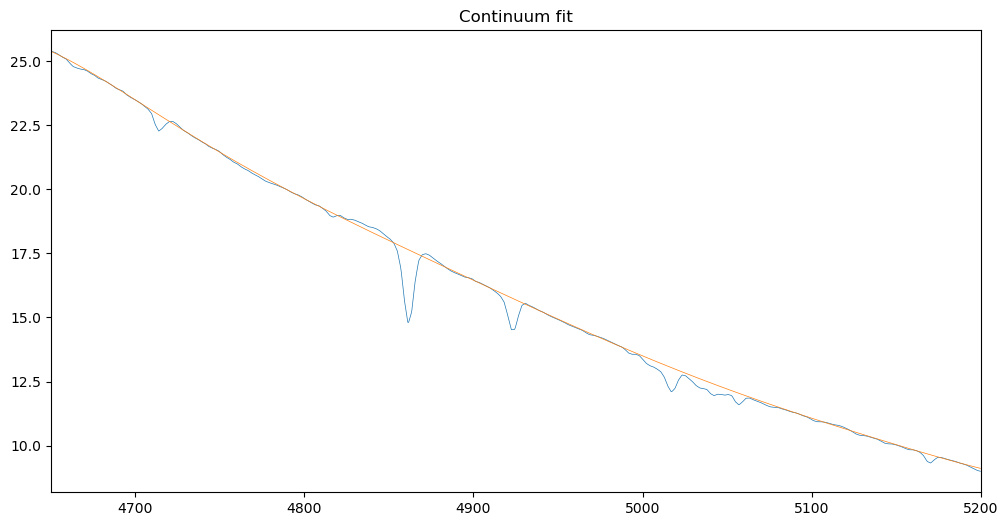

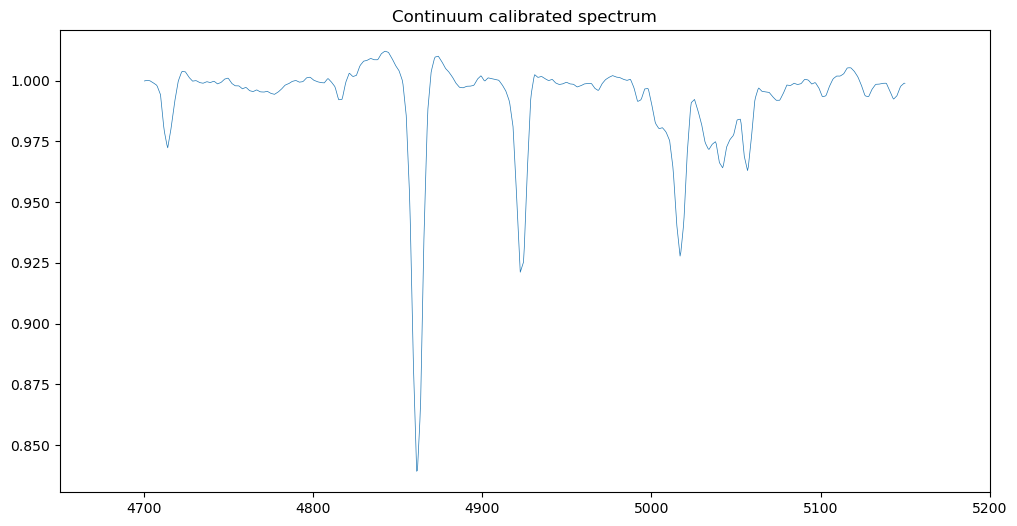

amp = -1.0377655703754534 
mu = 4861.548739616135 
sigma = 3.652648765560851 
gamma = -1.3348459650247761 
offset = 1.0 
chi2 = 0.000841719608712066


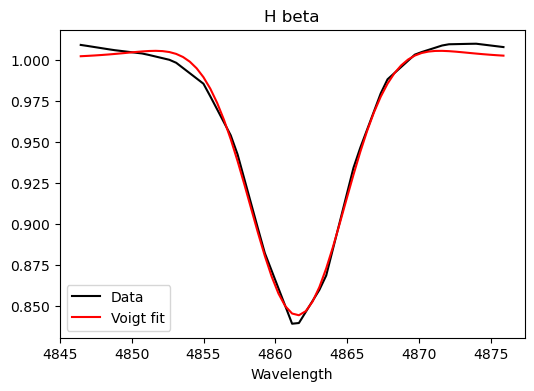

Lambda =  4861.548739616135 Eq Width = 1.0377655703754534 FWHM =  7.263389711540902 Intensity =  -0.15573261733553354


#### H beta optimization

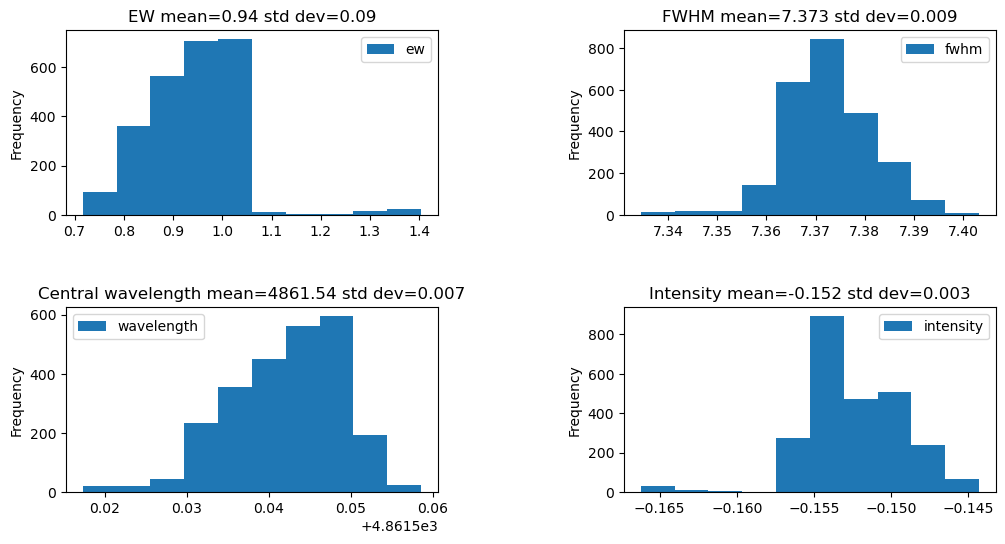

#### H beta re-fit with best parameters

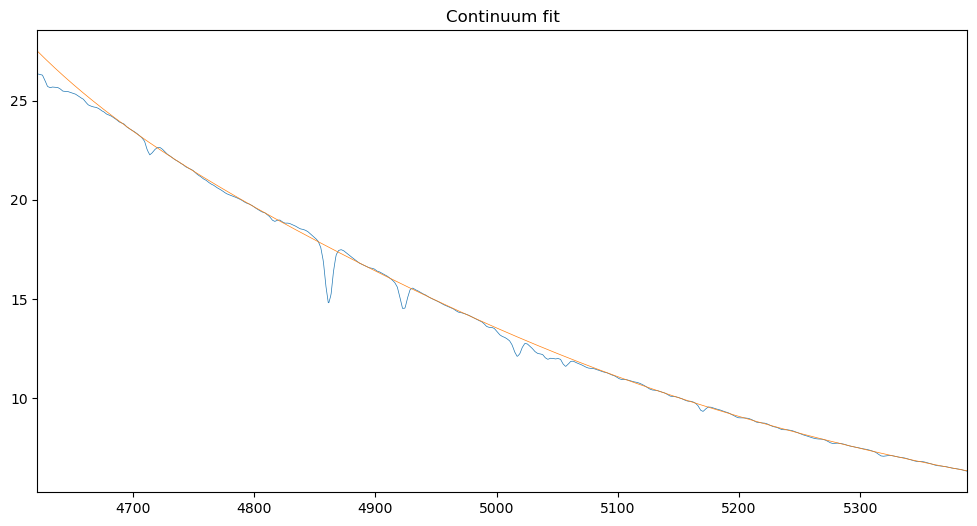

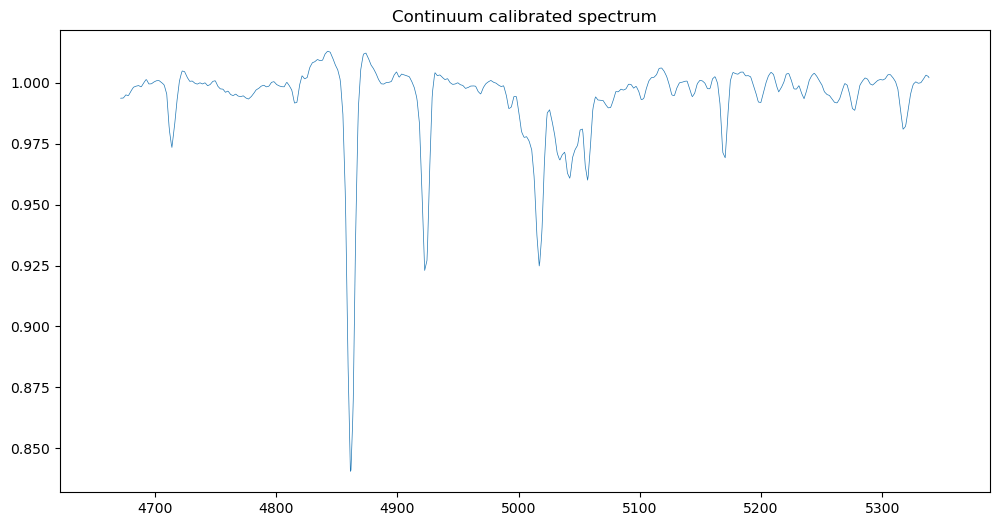

amp = -0.9406323872302809 
mu = 4861.538281702838 
sigma = 4.038256076828571 
gamma = -2.2035820414569947 
offset = 1.0 
chi2 = 0.0012286505537559816


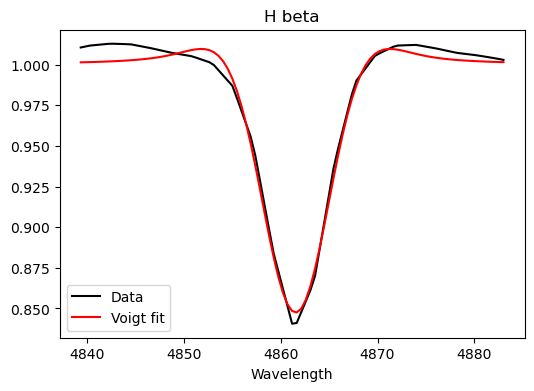

Lambda =  4861.538281702838 Eq Width = 0.9406323872302809 FWHM =  7.37198697551519 Intensity =  -0.15256767265176668


### Measuring H delta

#### H delta preliminary fit

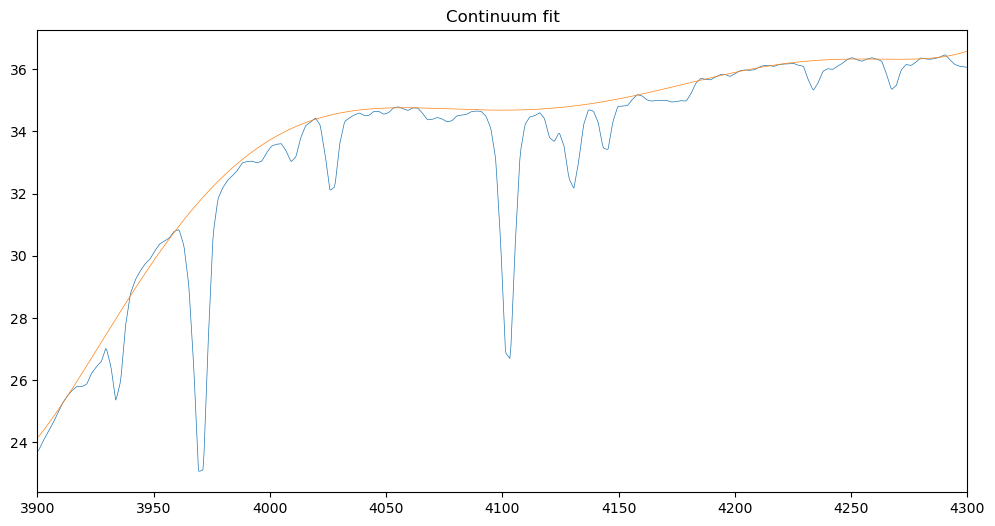

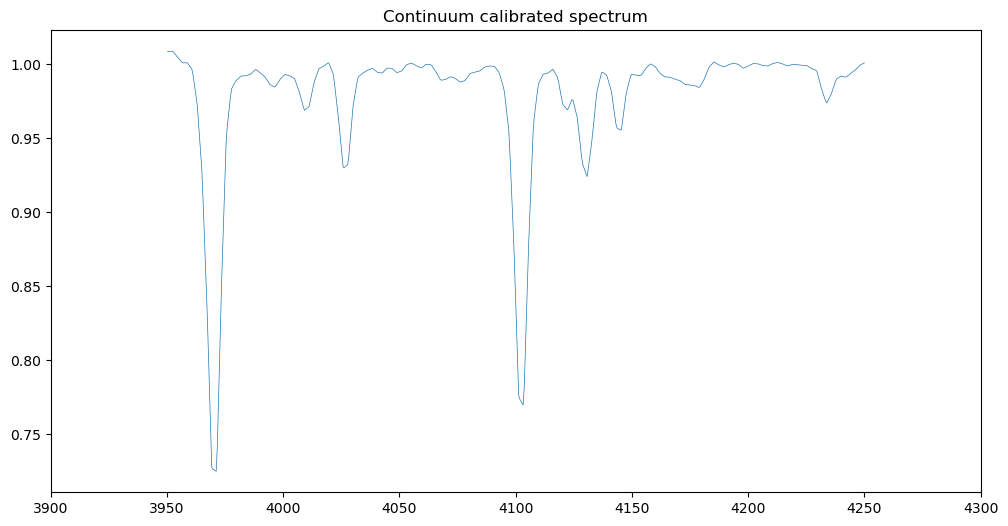

amp = -1.8389998844686435 
mu = 4102.3627989904935 
sigma = 2.447871592135943 
gamma = 0.8128532101808671 
offset = 1.0 
chi2 = 0.0004844244858911362


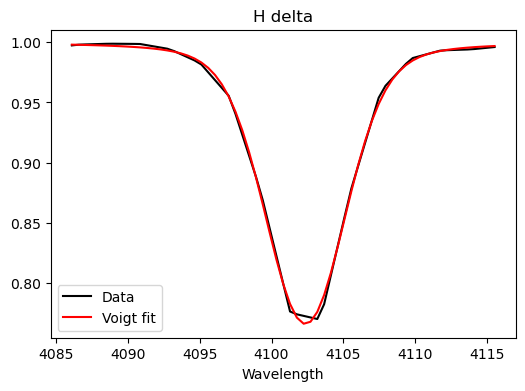

Lambda =  4102.3627989904935 Eq Width = 1.8389998844686435 FWHM =  6.682843078422633 Intensity =  -0.23430694918901873


#### H delta optimization

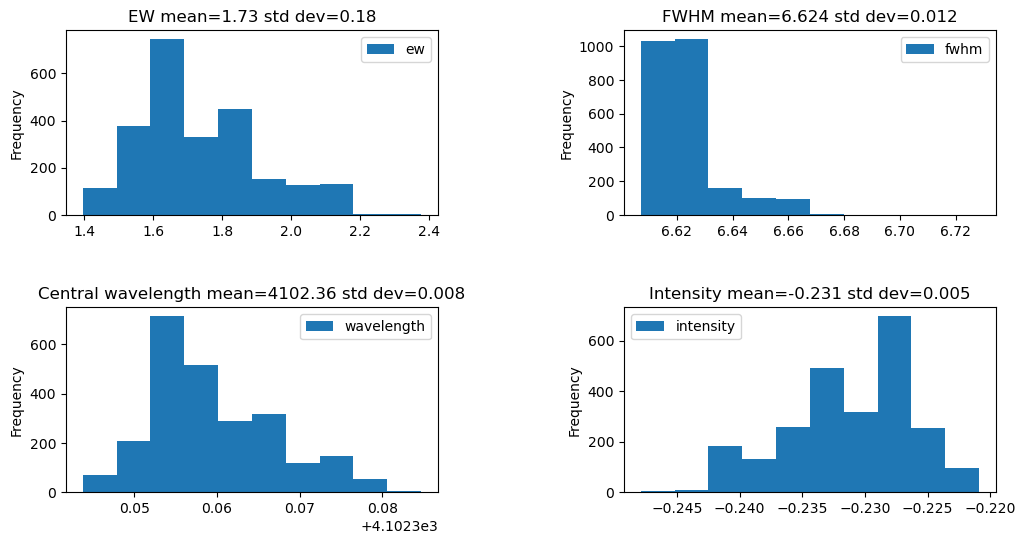

#### H delta re-fit with best parameters

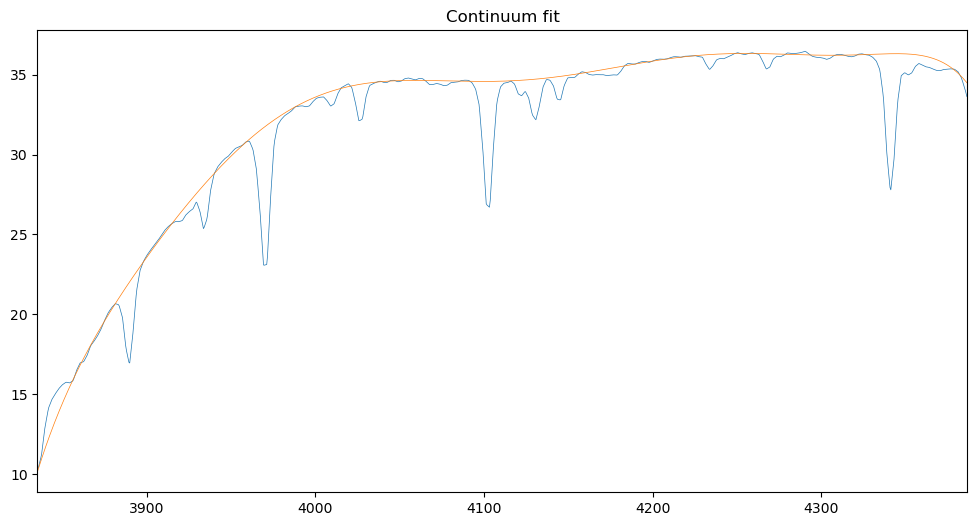

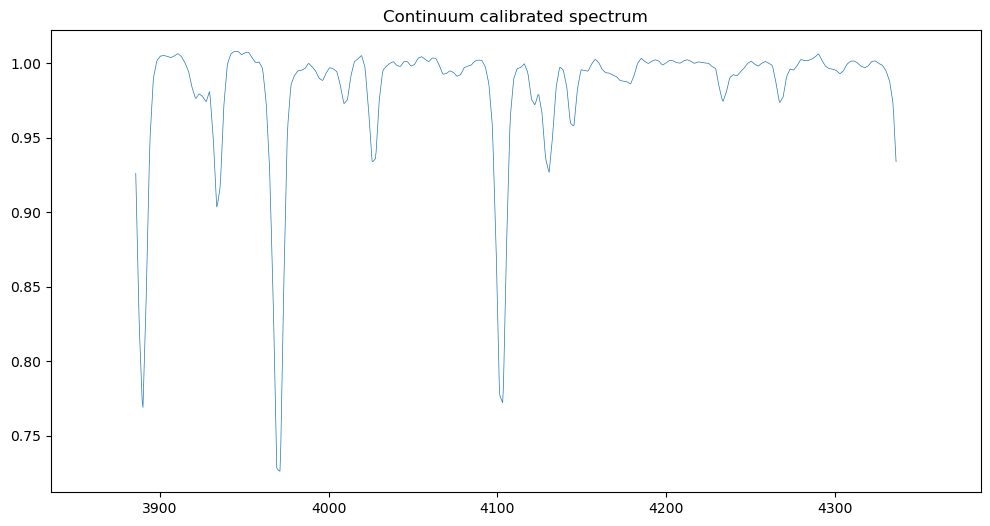

amp = -1.7536745396937108 
mu = 4102.364004645057 
sigma = 2.5378497133726095 
gamma = 0.5800732863481198 
offset = 1.0 
chi2 = 0.0005709101040477508


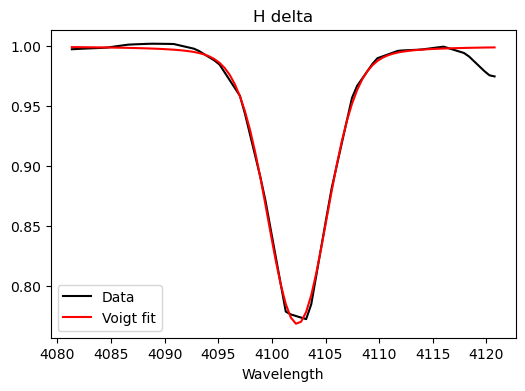

Lambda =  4102.364004645057 Eq Width = 1.7536745396937108 FWHM =  6.620735214923624 Intensity =  -0.2318087572899386


### Measuring Si II 6347

#### Si II 6347 preliminary fit

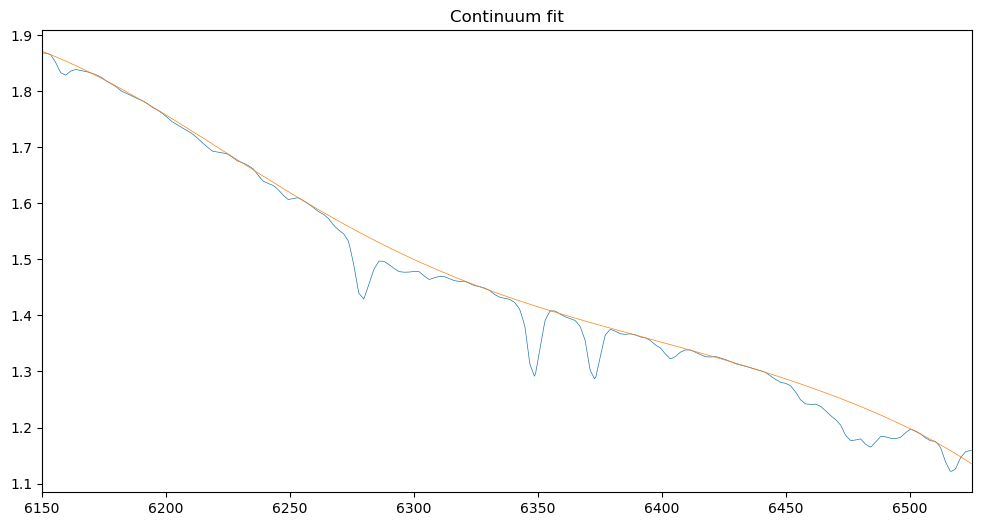

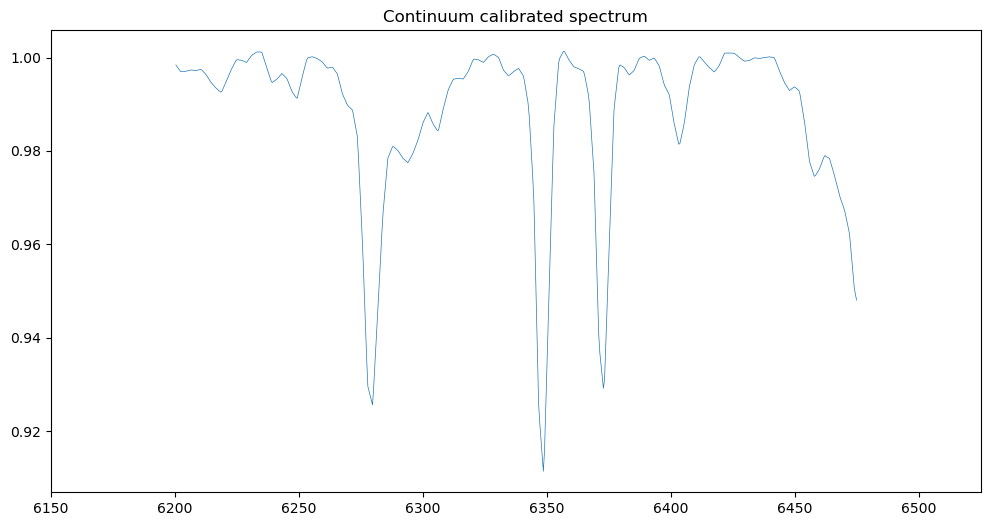

amp = -0.08629289080219596 
mu = 6348.276117155963 
sigma = 2.5584595153433147 
offset = 1.0 
chi2 =  9.042746218977047e-05


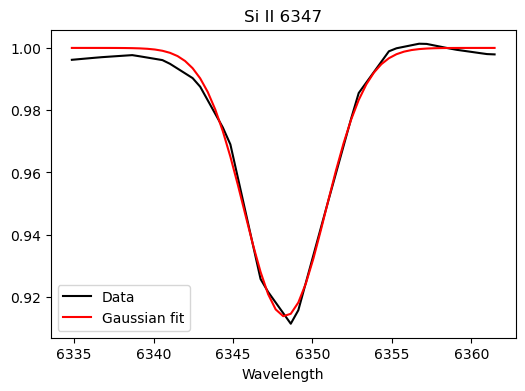

Lambda =  6348.276117155963 Eq Width = 0.5534055386588876 FWHM =  6.025172158633506 Intensity =  -0.08629289080219596


#### Si II 6347 optimization

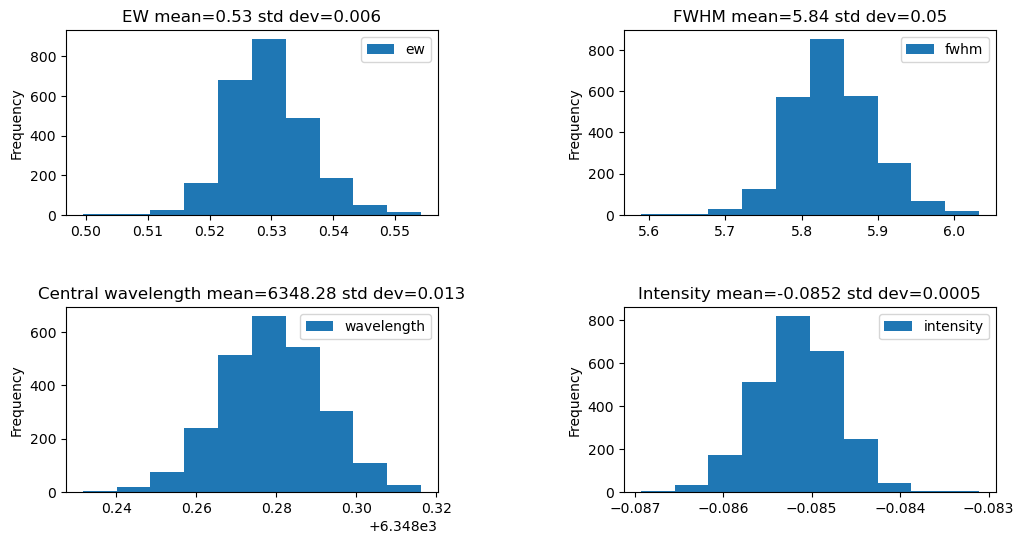

#### Si II 6347 re-fit with best parameters

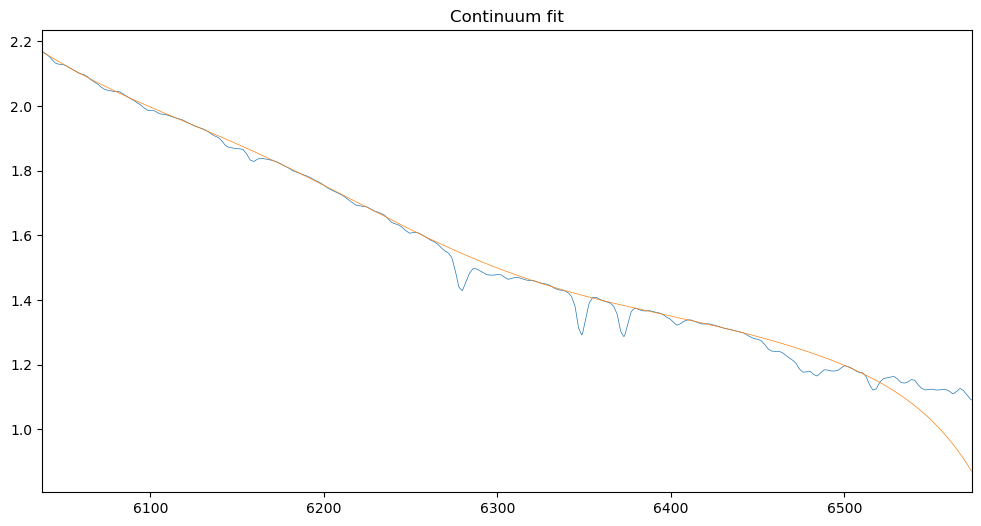

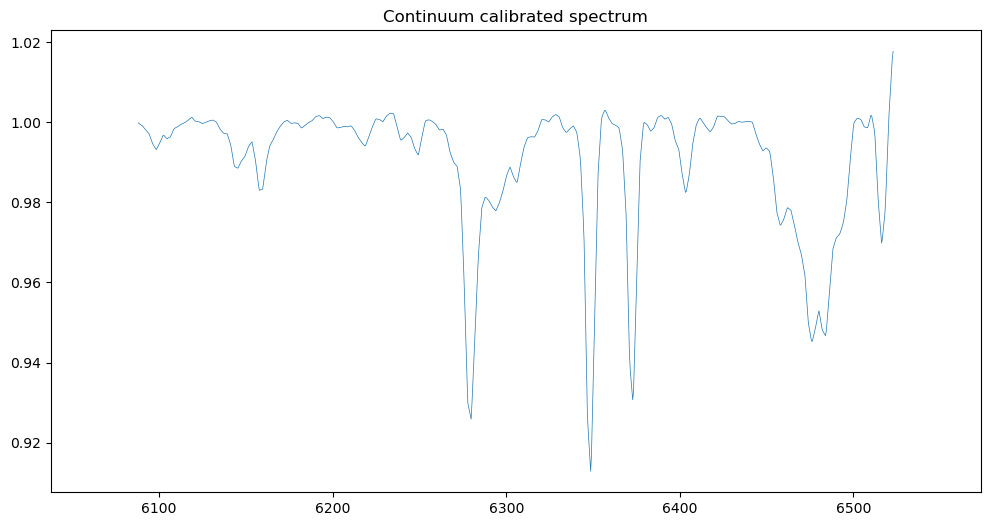

amp = -0.0853265515903198 
mu = 6348.276746378467 
sigma = 2.490740211267377 
offset = 1.0 
chi2 =  7.993707265795945e-05


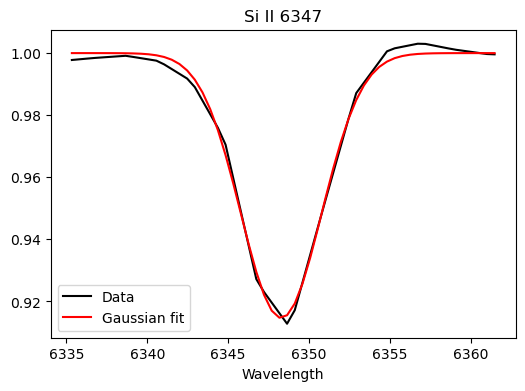

Lambda =  6348.276746378467 Eq Width = 0.532724365341615 FWHM =  5.865693197534673 Intensity =  -0.0853265515903198


### Measuring Si II 6371

#### Si II 6371 preliminary fit

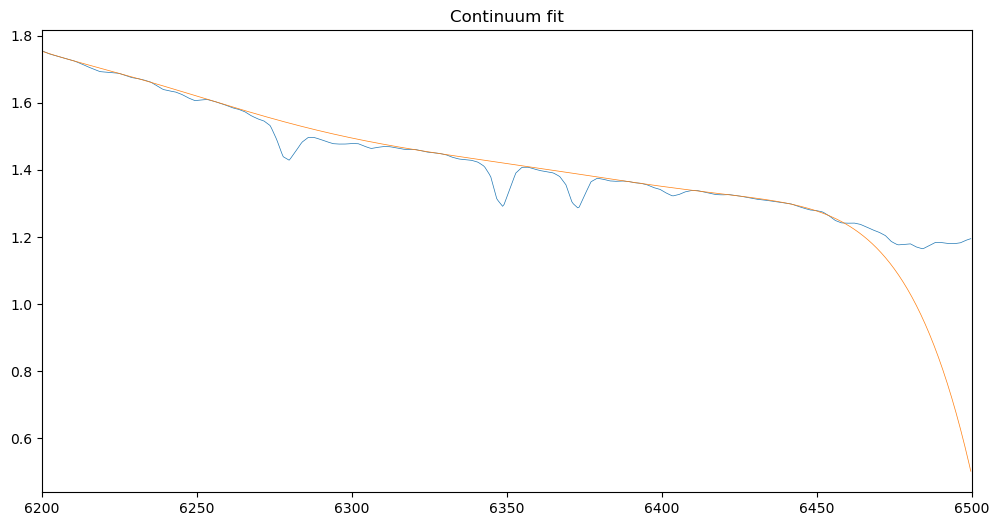

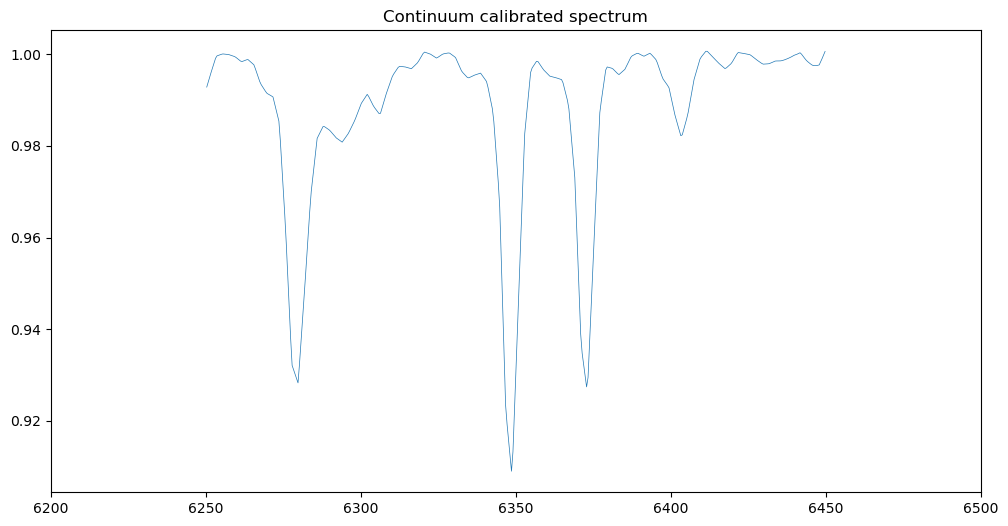

amp = -0.07056810878635872 
mu = 6372.489954194546 
sigma = 2.6748546857789752 
offset = 1.0 
chi2 =  0.00010941104025410615


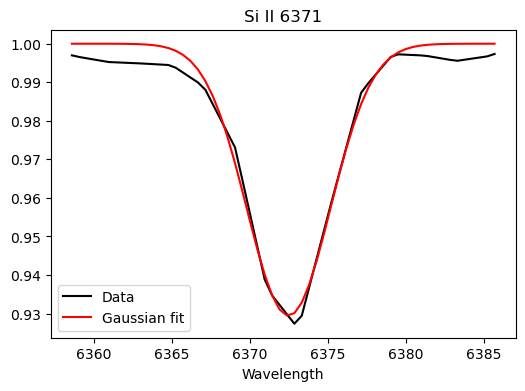

Lambda =  6372.489954194546 Eq Width = 0.47314974051838854 FWHM =  6.299282785009487 Intensity =  -0.07056810878635872


#### Si II 6371 optimization

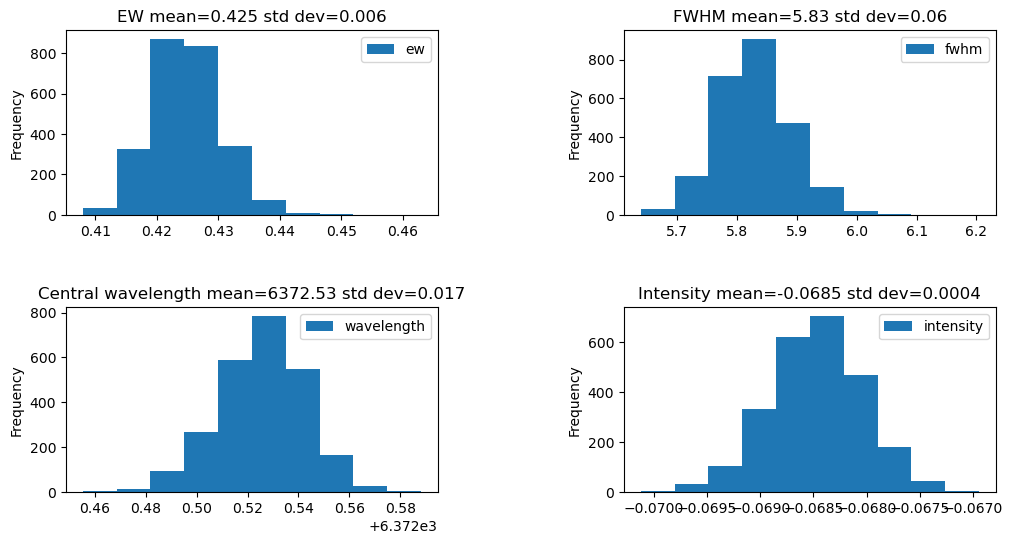

#### Si II 6371 re-fit with best parameters

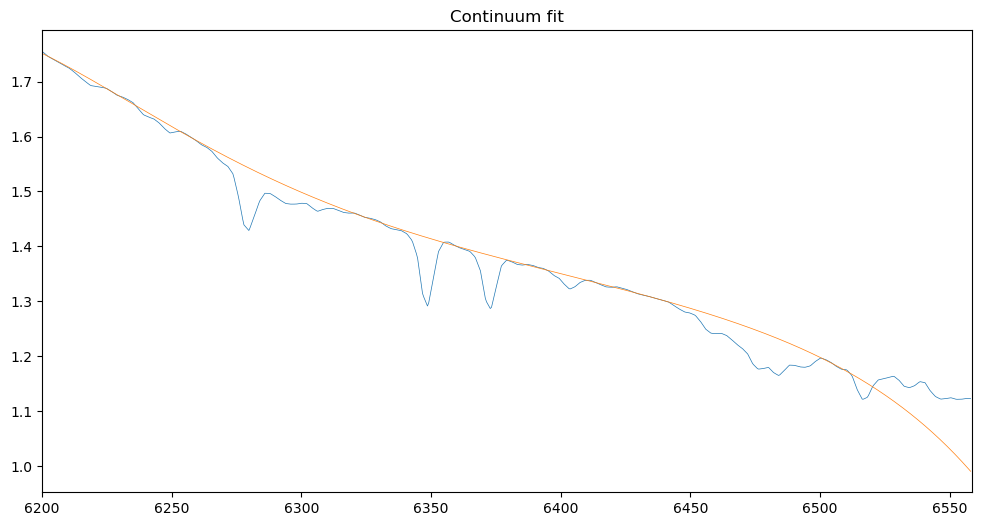

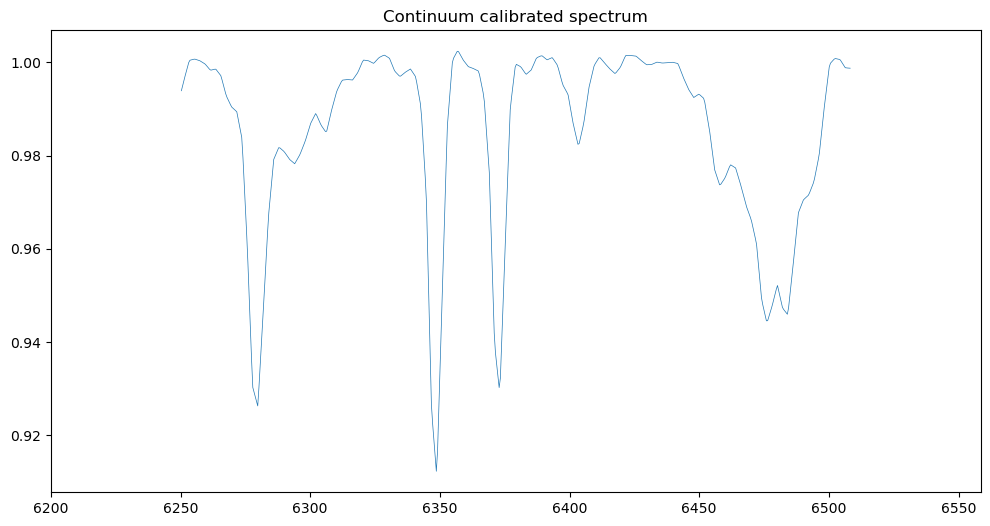

amp = -0.06877522273862509 
mu = 6372.523164404225 
sigma = 2.499938274216738 
offset = 1.0 
chi2 =  5.0885982814645434e-05


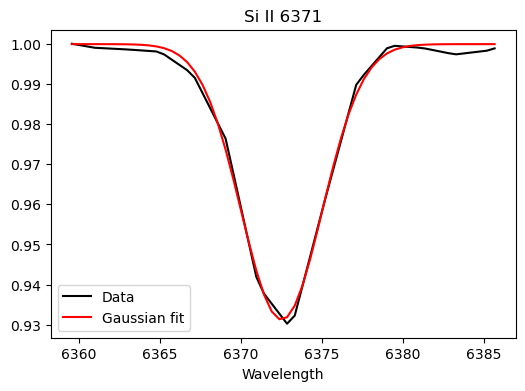

Lambda =  6372.523164404225 Eq Width = 0.4309741536270937 FWHM =  5.887354635780418 Intensity =  -0.06877522273862509


### Measuring He I 4026

#### He I 4026 preliminary fit

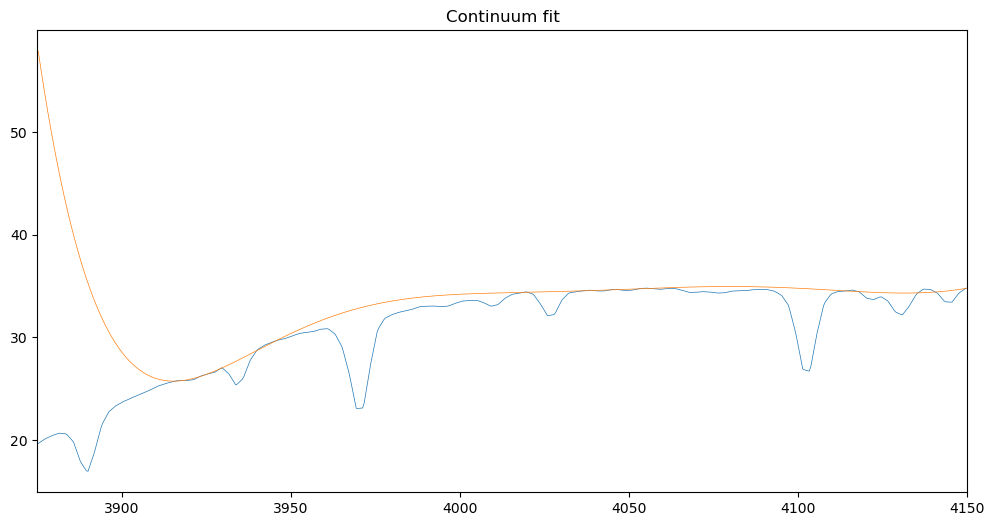

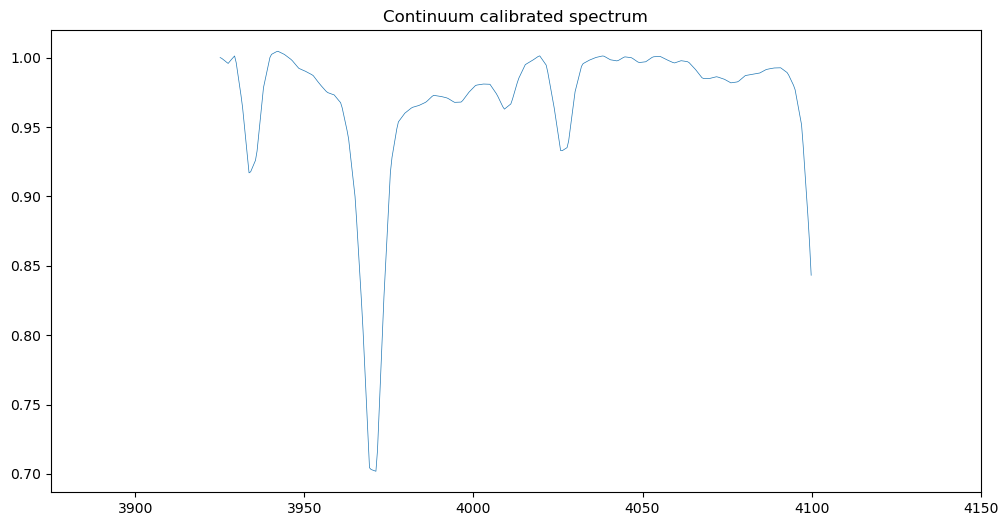

amp = -0.06897832029832975 
mu = 4026.668213891888 
sigma = 2.449839522902127 
offset = 1.0 
chi2 =  4.742667439895446e-05


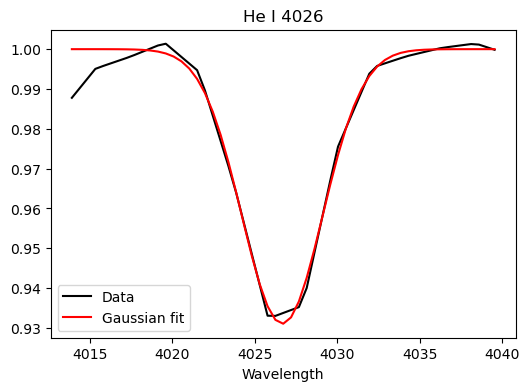

Lambda =  4026.668213891888 Eq Width = 0.4235846226181128 FWHM =  5.769372076434508 Intensity =  -0.06897832029832975


#### He I 4026 optimization

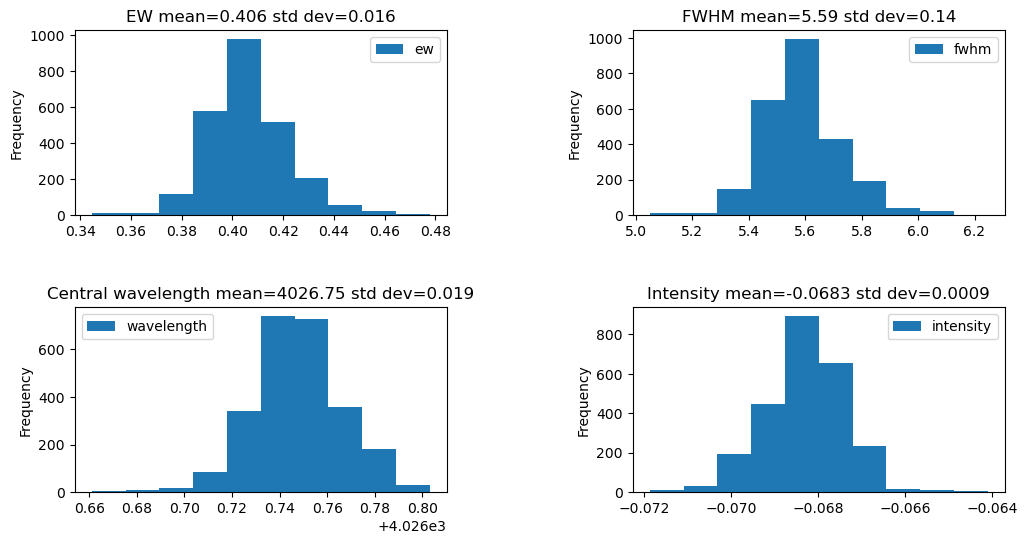

#### He I 4026 re-fit with best parameters

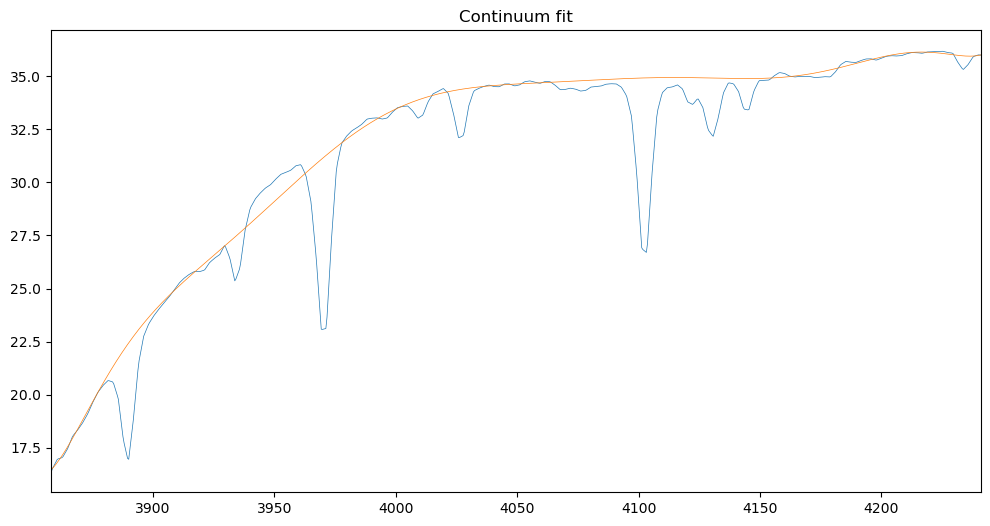

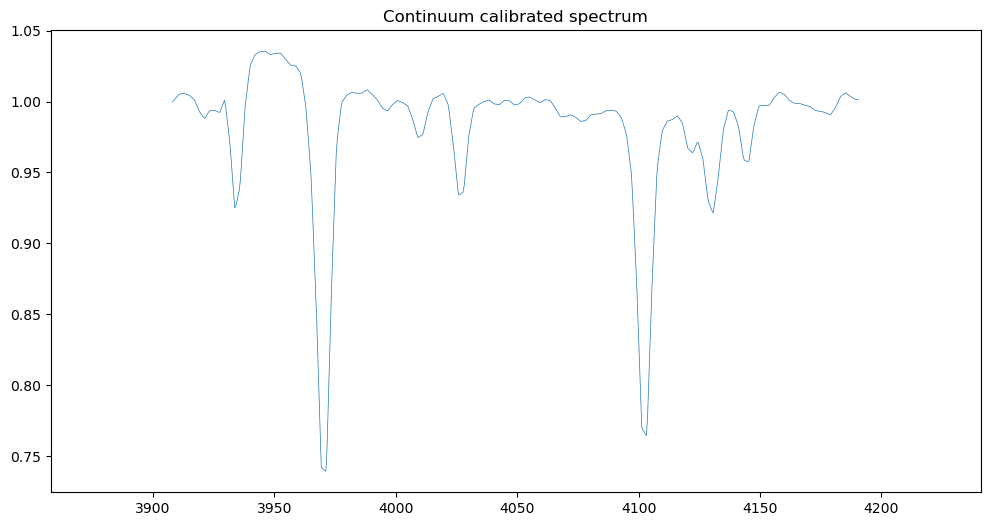

amp = -0.06829956647011347 
mu = 4026.7371267242092 
sigma = 2.370151818550754 
offset = 1.0 
chi2 =  6.666138724919639e-05


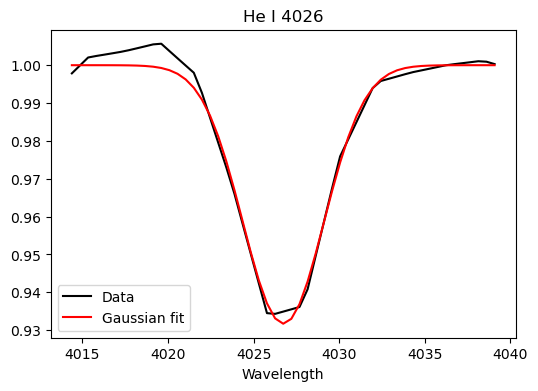

Lambda =  4026.7371267242092 Eq Width = 0.40577384155040336 FWHM =  5.581707532687026 Intensity =  -0.06829956647011347


### Measuring He I 4388

#### He I 4388 preliminary fit

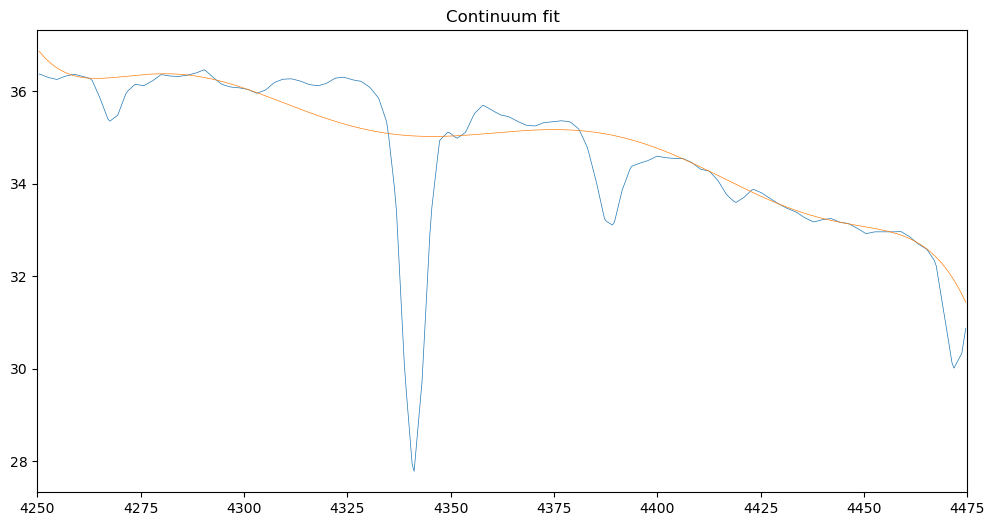

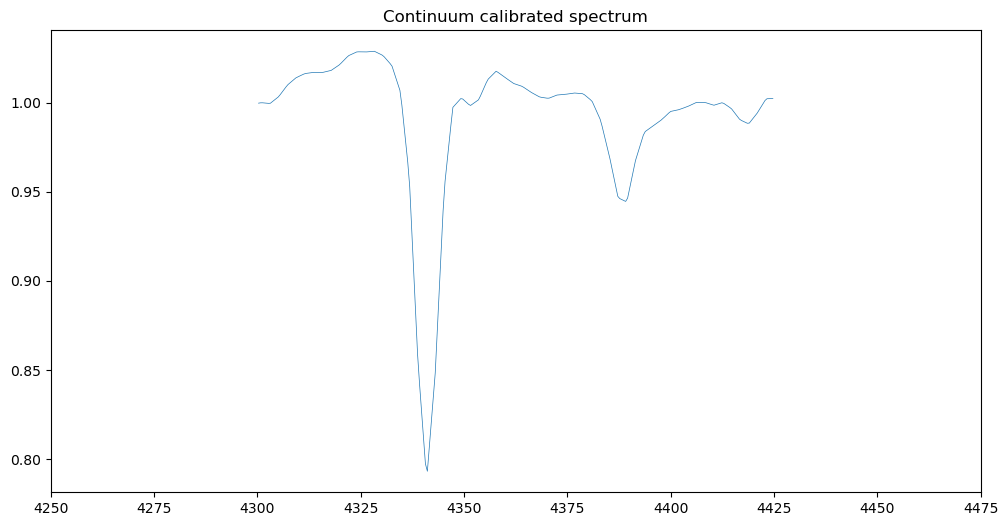

amp = -0.05378322901294308 
mu = 4388.695920868625 
sigma = 3.295500380579222 
offset = 1.0 
chi2 =  0.0003776926750162419


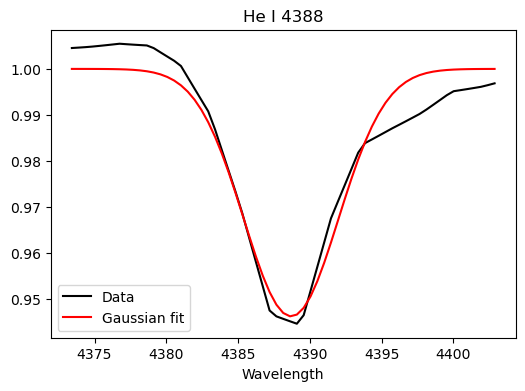

Lambda =  4388.695920868625 Eq Width = 0.44428144217400134 FWHM =  7.760903396264068 Intensity =  -0.05378322901294308


#### He I 4388 optimization

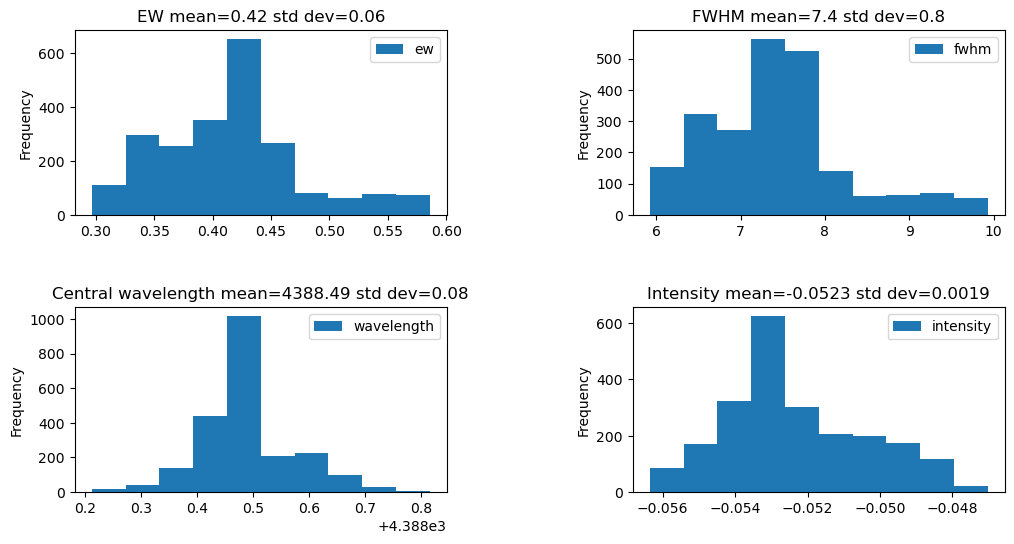

#### He I 4388 re-fit with best parameters

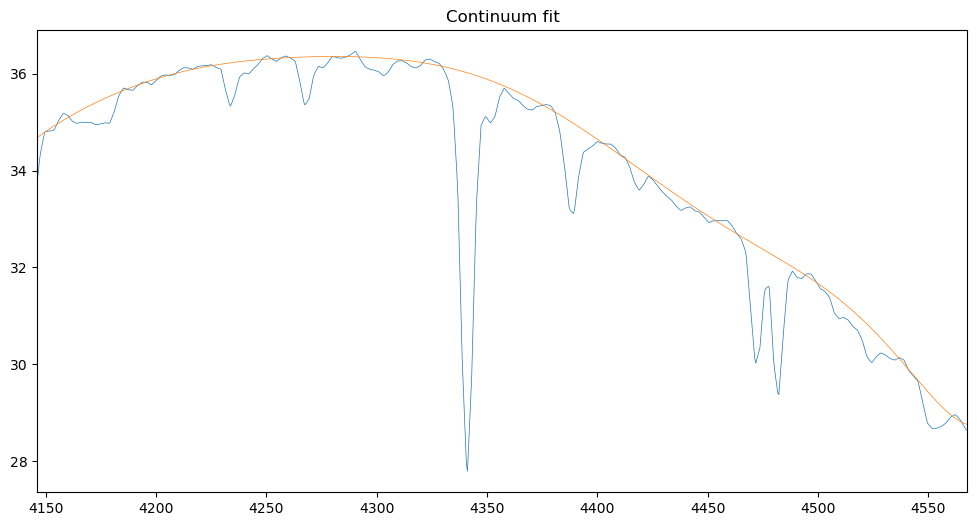

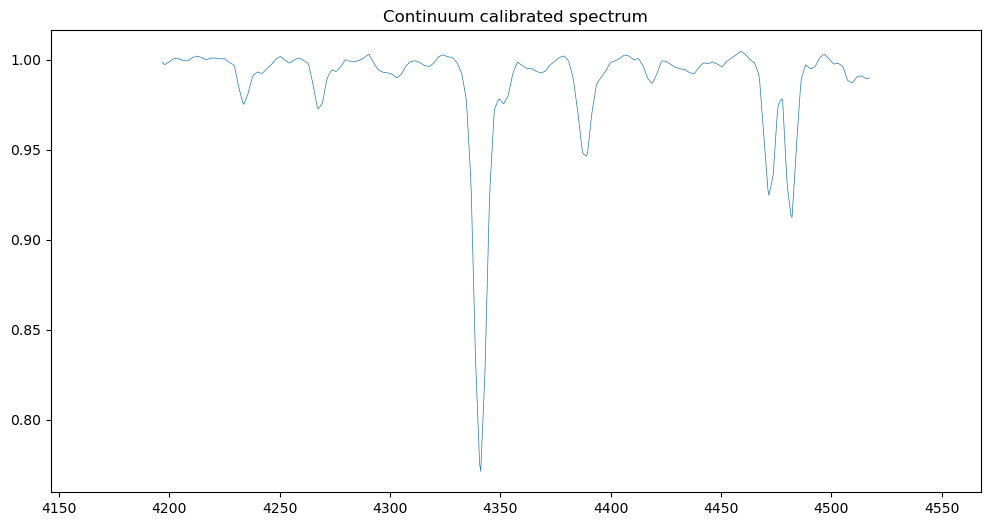

amp = -0.05258317430067232 
mu = 4388.493747352934 
sigma = 3.149289158819743 
offset = 1.0 
chi2 =  0.00015428044895337417


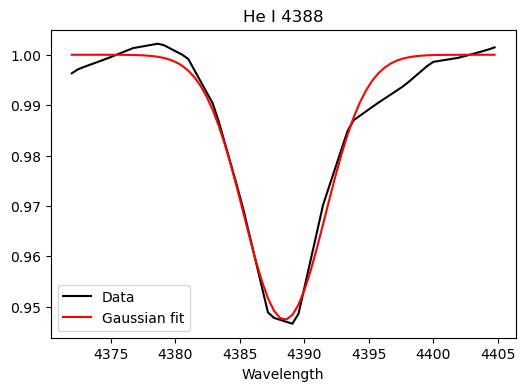

Lambda =  4388.493747352934 Eq Width = 0.41509669166878693 FWHM =  7.416575969020495 Intensity =  -0.05258317430067232


### Measuring He I 4922

#### He I 4922 preliminary fit

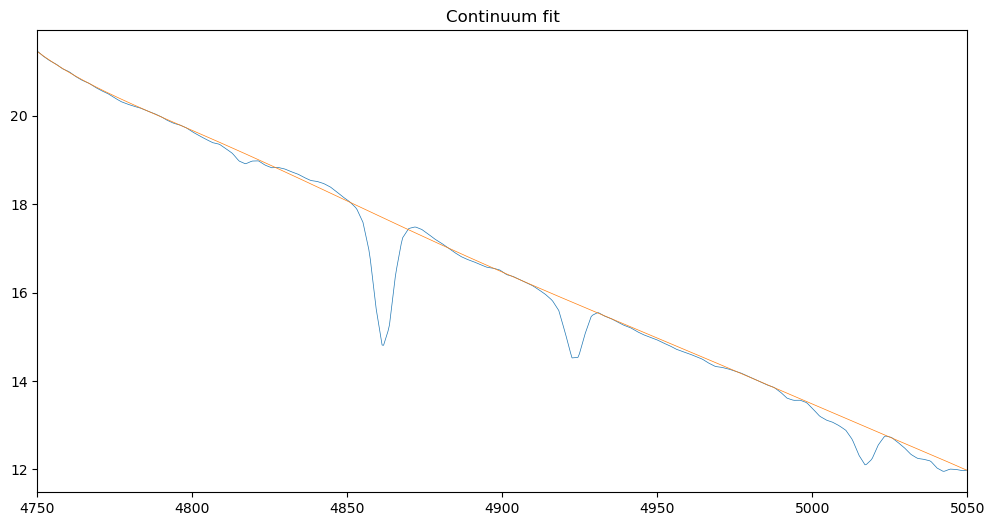

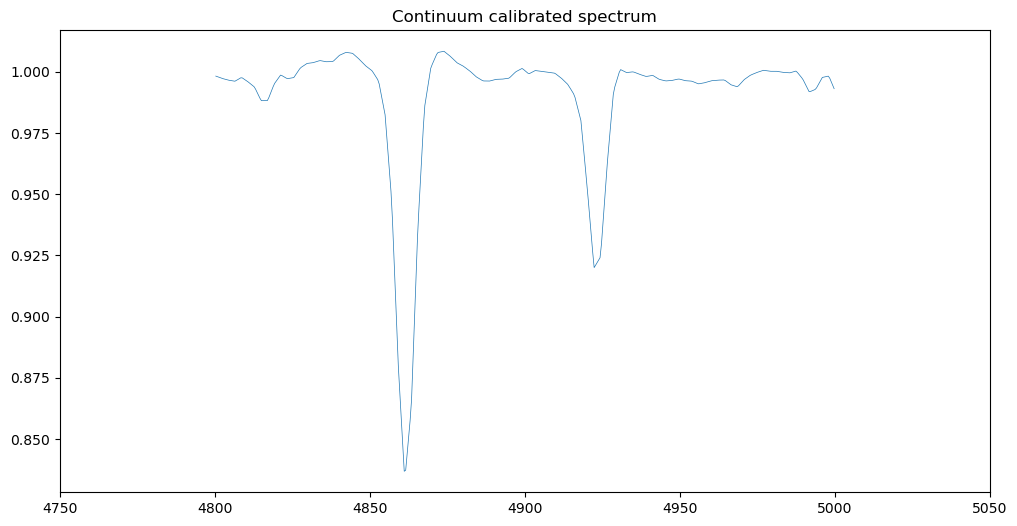

amp = -0.0795238048460478 
mu = 4923.060445001094 
sigma = 2.9582247451727715 
offset = 1.0 
chi2 =  0.00018160571214226185


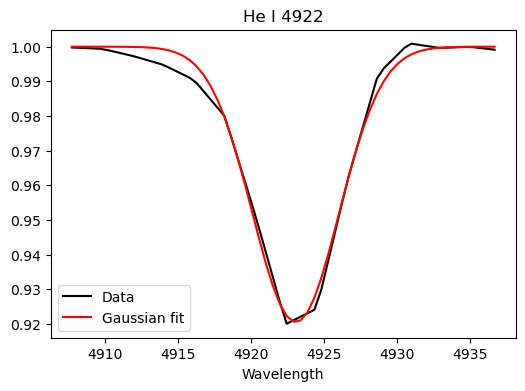

Lambda =  4923.060445001094 Eq Width = 0.5896825151978153 FWHM =  6.966619274881877 Intensity =  -0.0795238048460478


#### He I 4922 optimization

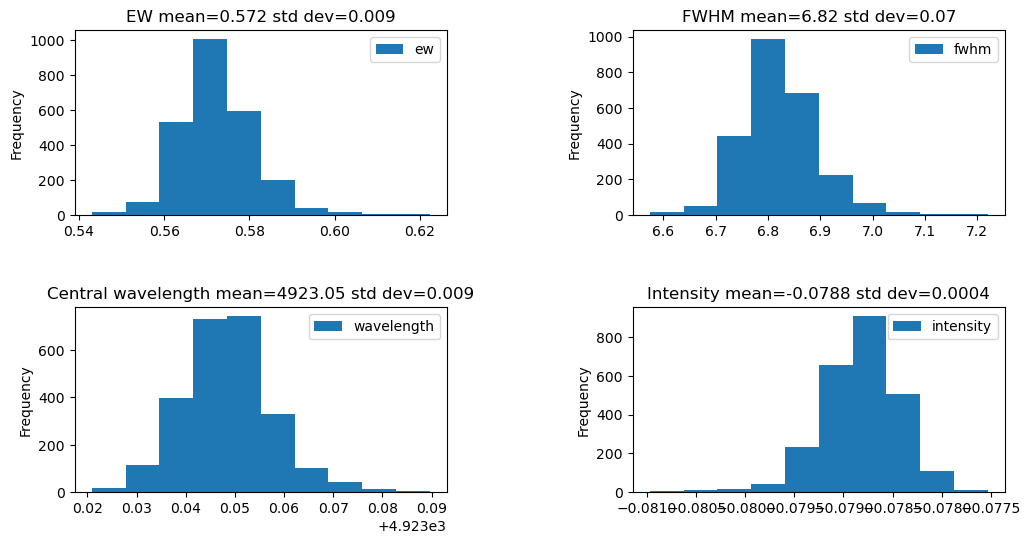

#### He I 4922 re-fit with best parameters

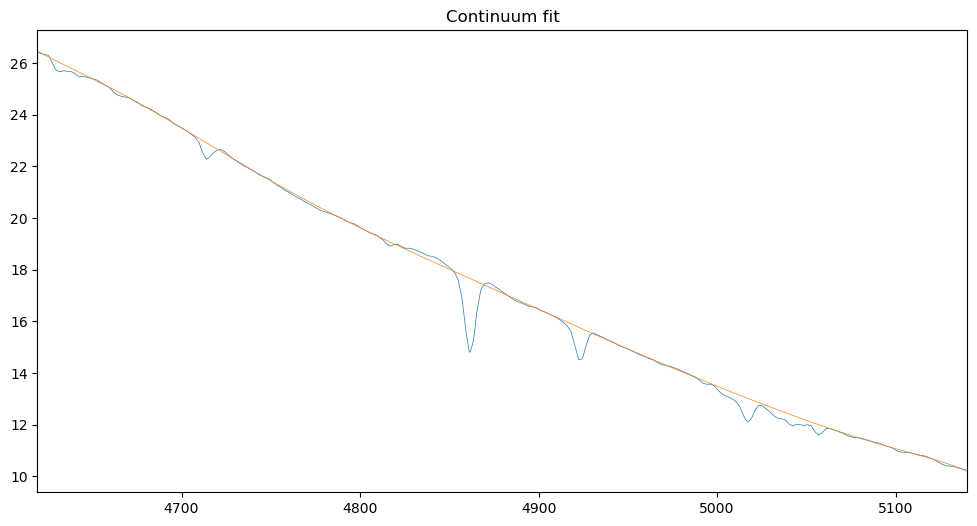

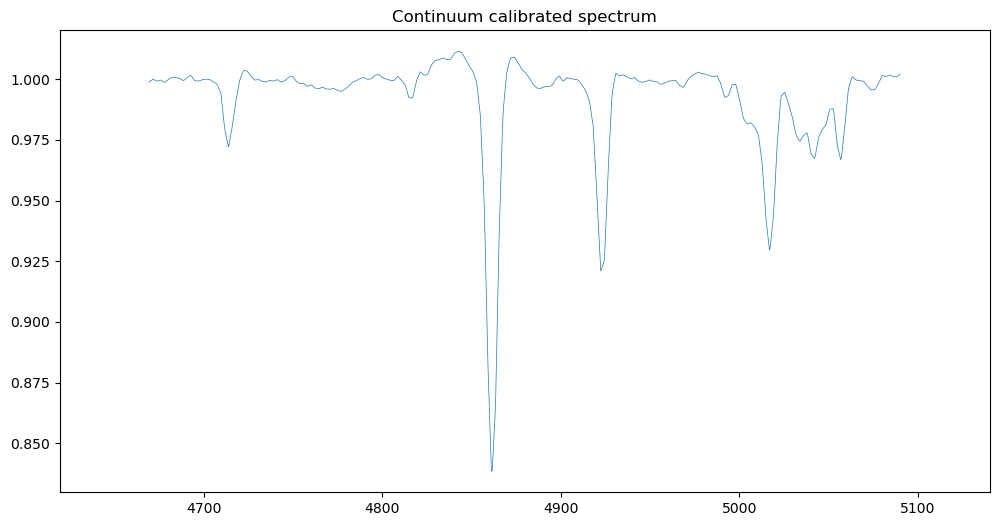

amp = -0.07886519576832048 
mu = 4923.046962336417 
sigma = 2.9007092970196138 
offset = 1.0 
chi2 =  0.0001957955955571606


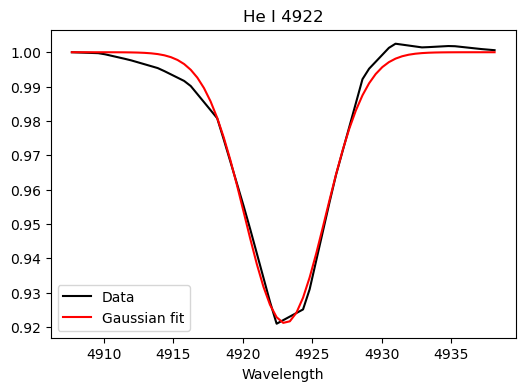

Lambda =  4923.046962336417 Eq Width = 0.573428833730649 FWHM =  6.83117039448119 Intensity =  -0.07886519576832048


### Measuring He I 6678

#### He I 6678 preliminary fit

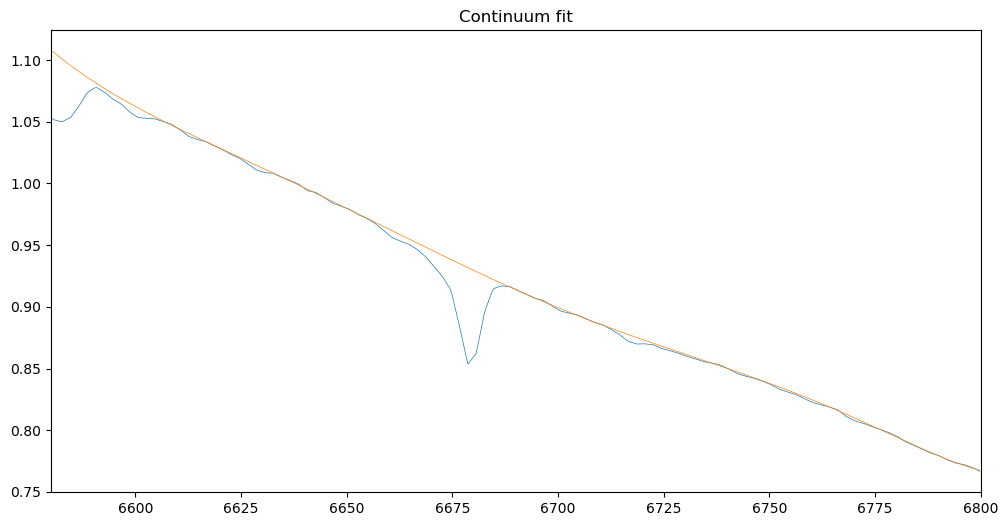

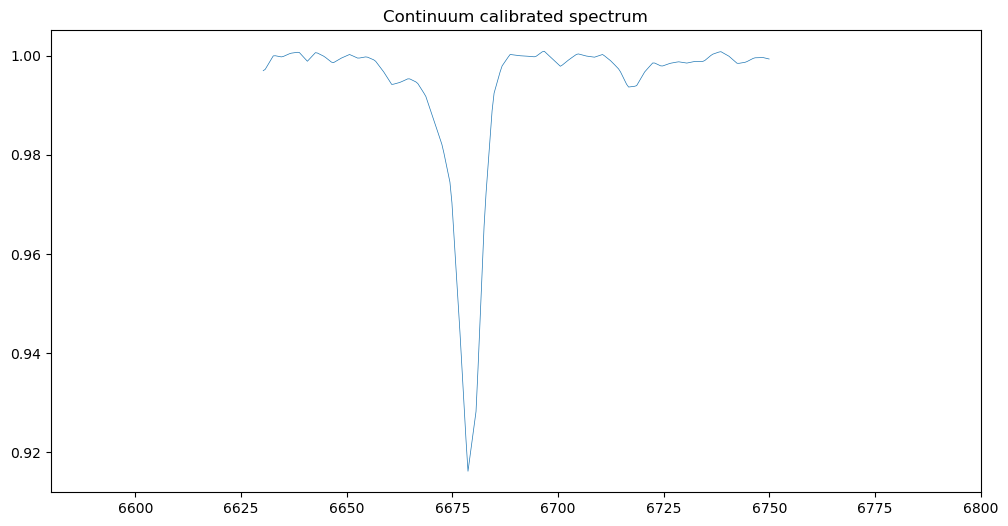

amp = -0.07762477600593555 
mu = 6678.872833491695 
sigma = 3.0602972610701737 
offset = 1.0 
chi2 =  0.0006553082913667515


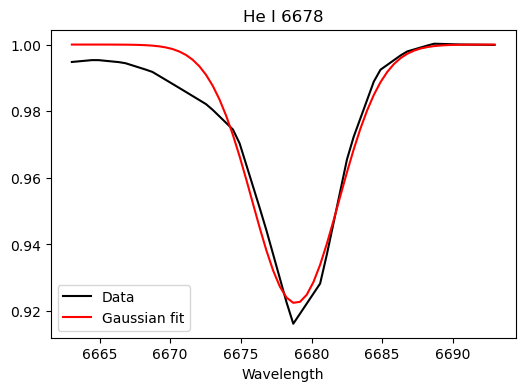

Lambda =  6678.872833491695 Eq Width = 0.5954618025522701 FWHM =  7.207000049820259 Intensity =  -0.07762477600593555


#### He I 6678 optimization

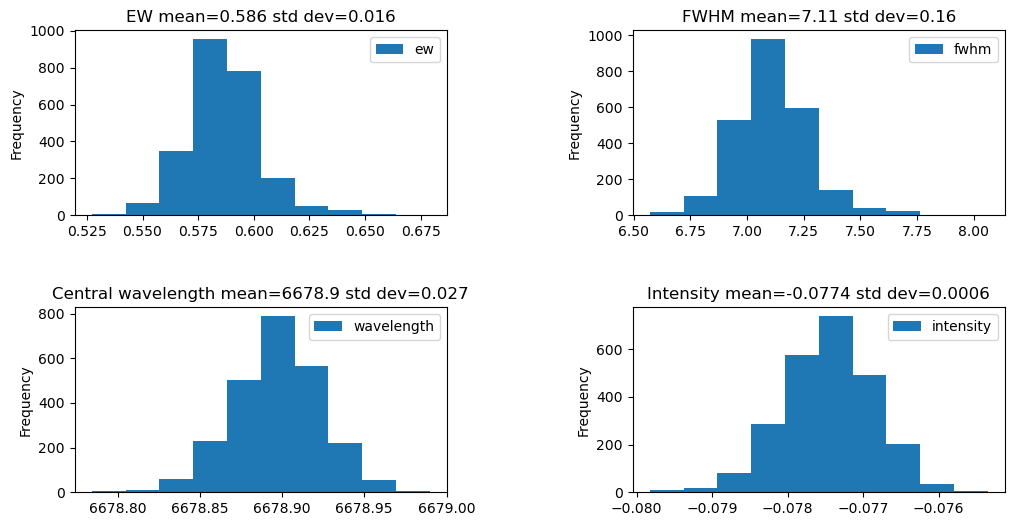

#### He I 6678 re-fit with best parameters

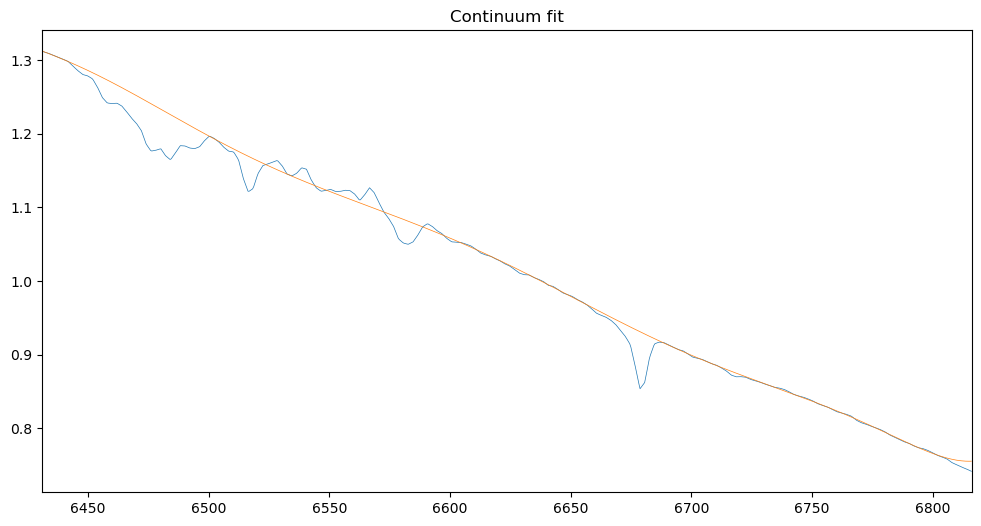

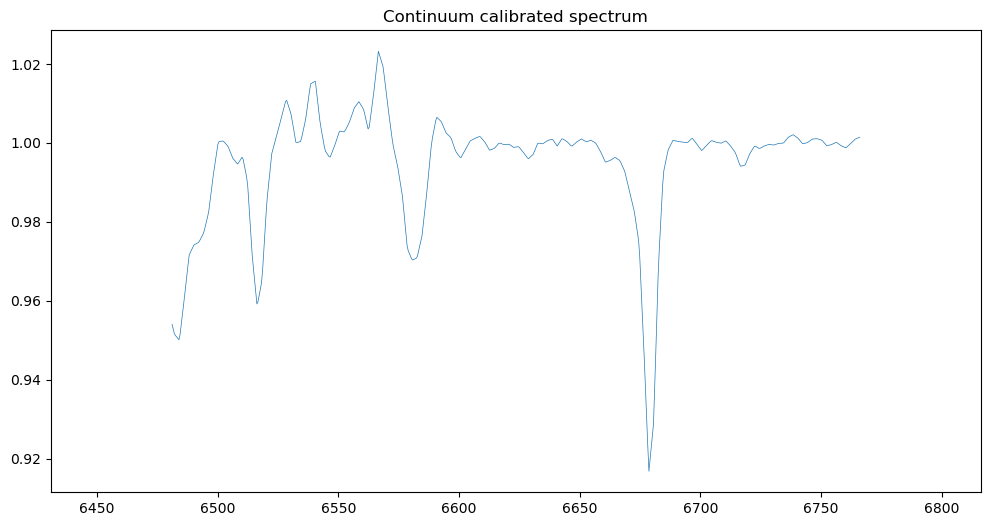

amp = -0.07736904617663438 
mu = 6678.890287359177 
sigma = 3.0102817029217506 
offset = 1.0 
chi2 =  0.0006079850617324794


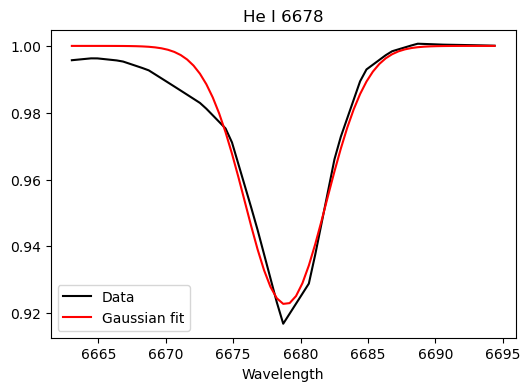

Lambda =  6678.890287359177 Eq Width = 0.583800302749746 FWHM =  7.089213410380722 Intensity =  -0.07736904617663438


In [29]:
summary_results = pd.DataFrame(columns=("line_name","wavelength","delta_wavelength","ew","delta_ew","fwhm","delta_fwhm","intensity","delta_intensity"))

i = 0

for measuring_line in measuring_lines:
    results = measure_line(wl, flux, measuring_line, show_param_dependencies=SHOW_PARAM_DEPENDENCIES)
    summary_results.loc[i] = results
    i = i + 1

## Measure All Blends

### Measuring H gamma

Blended lines= [{'name': 'H gamma', 'wavelength': 4341.0}, {'name': 'Fe II 4352', 'wavelength': 4352.0}]


#### H gamma preliminary fit

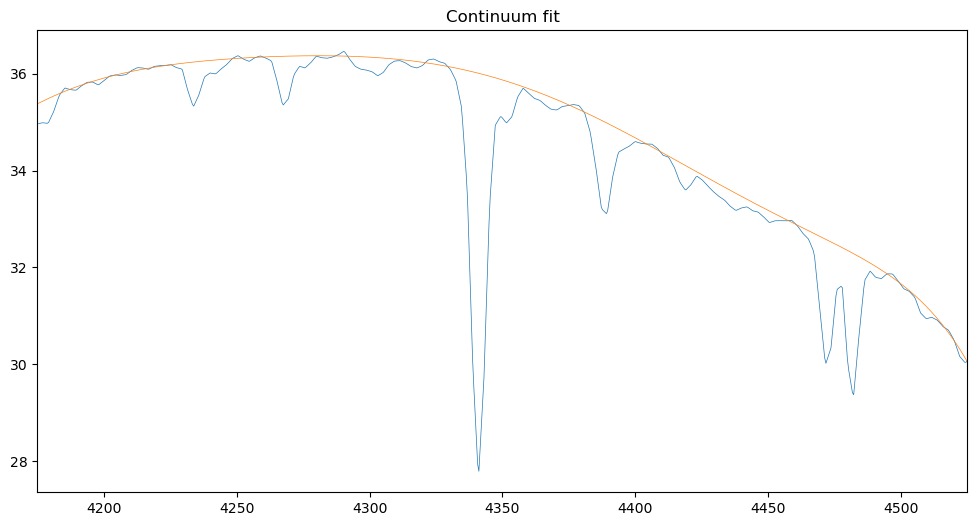

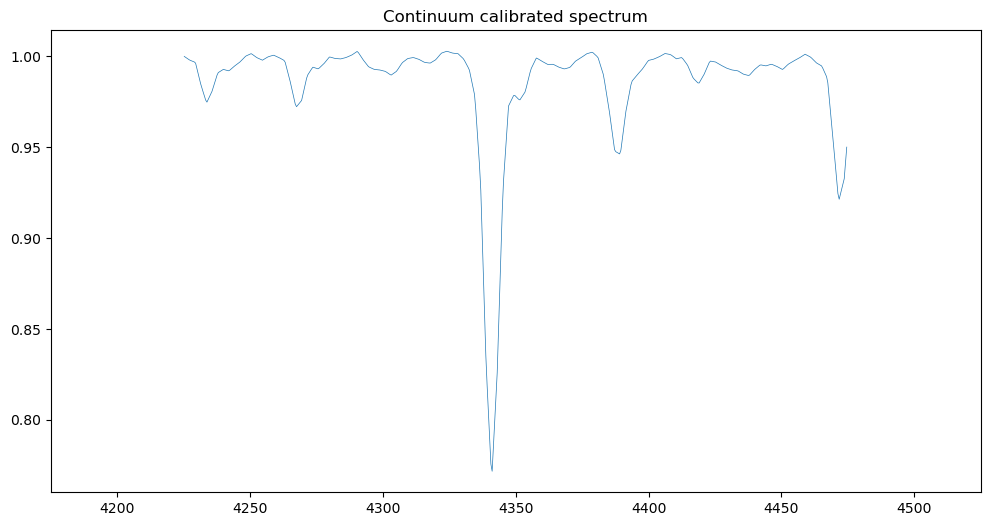

H gamma (gauss)
amp = -0.21987146877058503 
mu = 4340.981625751756 
sigma = 2.896922622277506 
offset = 1.0 
chi2 = 0.0007634100582939296


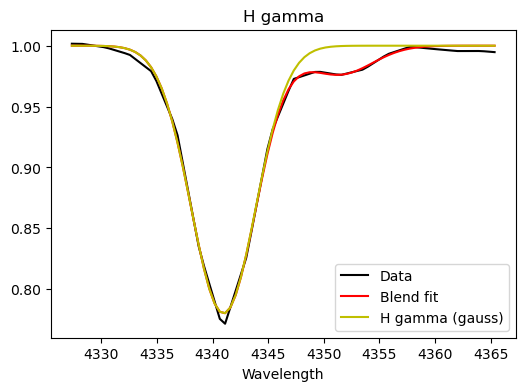

Fe II 4352 (gauss)
amp = -0.023573520616965542 
mu = 4351.401159240296 
sigma = 2.9541825491382707 
offset = 1.0 
chi2 = 0.0007634100582939296


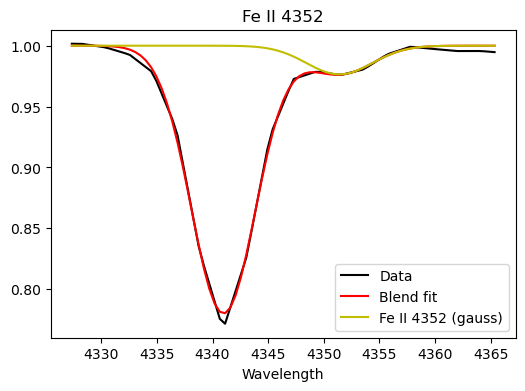

#### H gamma optimization

#### Plotting results for H gamma

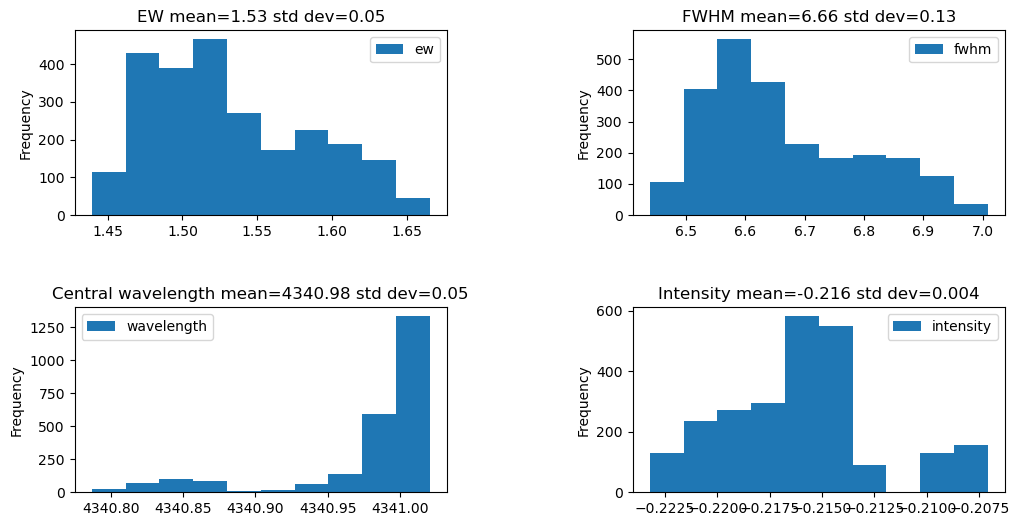

#### Plotting results for Fe II 4352

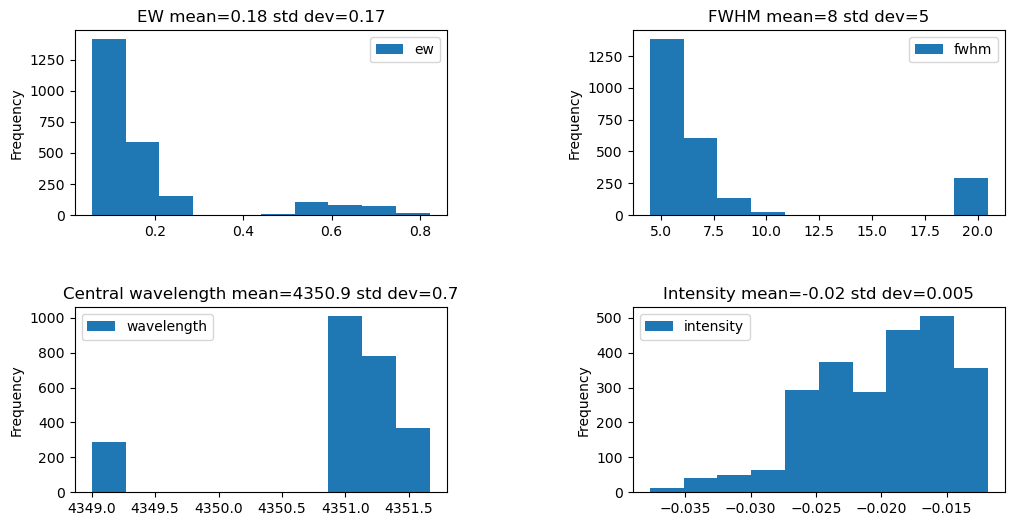

#### H gamma re-fit with best parameters

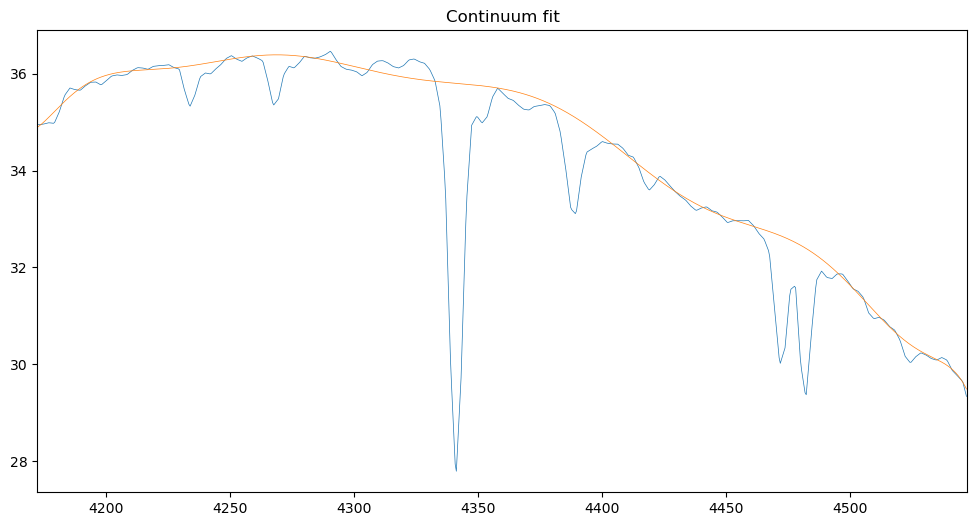

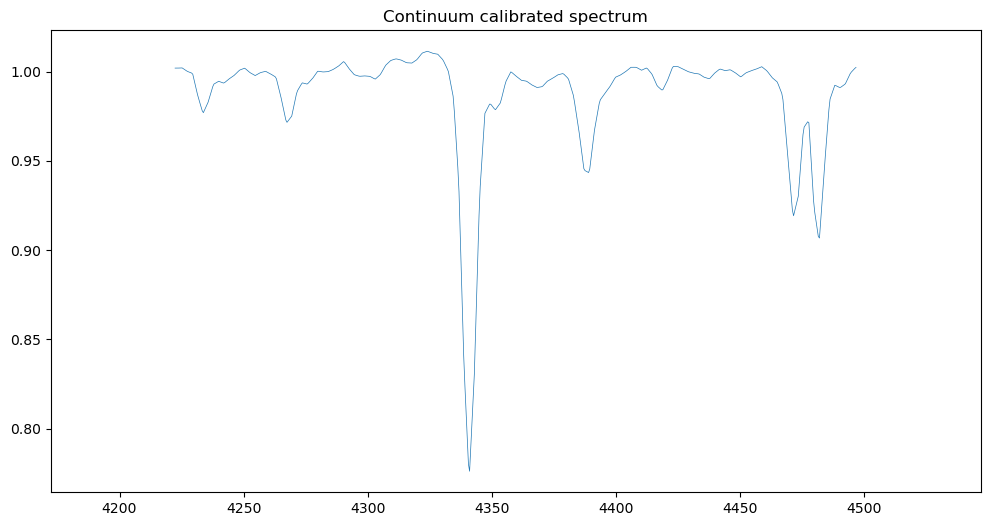

H gamma (gauss)
amp = -0.21686882511233344 
mu = 4341.010174923306 
sigma = 2.797420786969714 
offset = 1.0 
chi2 = 0.001226737800417737


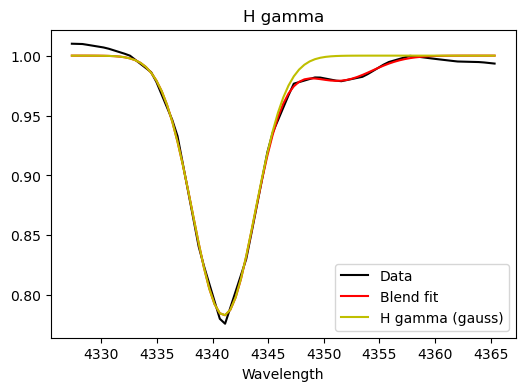

Fe II 4352 (gauss)
amp = -0.020791480831760207 
mu = 4351.33613382766 
sigma = 2.987535595506085 
offset = 1.0 
chi2 = 0.001226737800417737


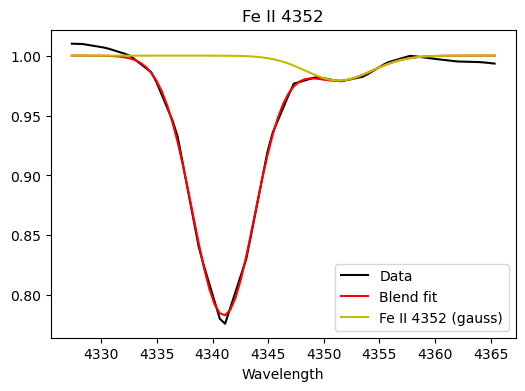

### Measuring Mg II 4481

Blended lines= [{'name': 'Mg II 4481', 'wavelength': 4481.0}, {'name': 'He I 4471', 'wavelength': 4470.0}]


#### Mg II 4481 preliminary fit

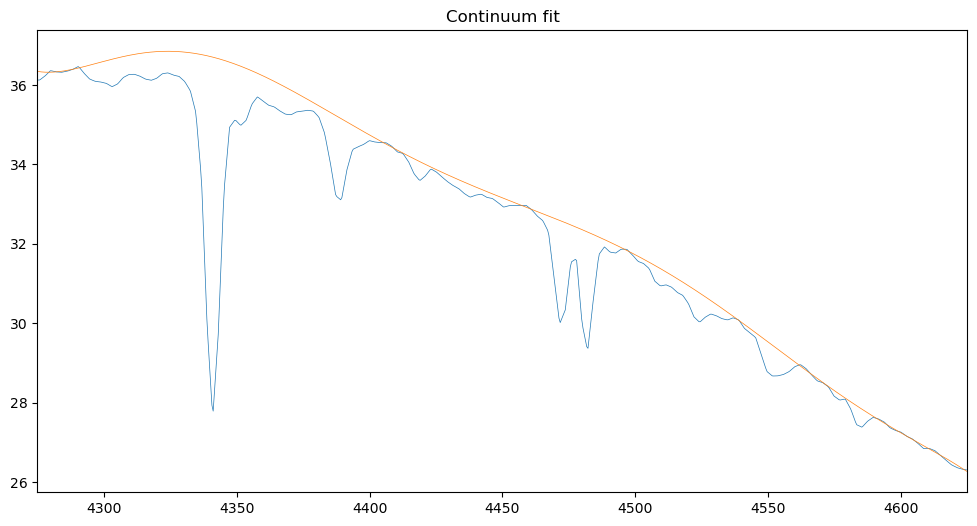

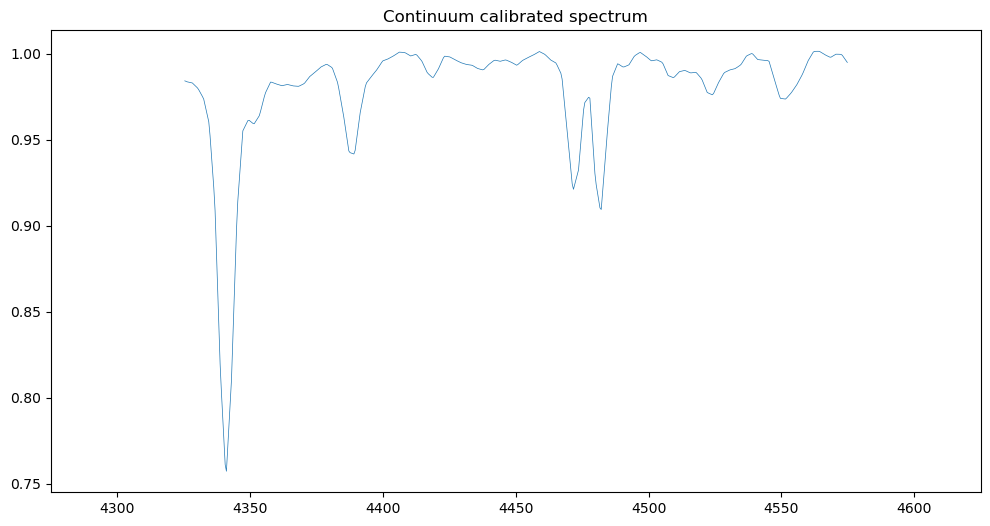

Mg II 4481 (gauss)
amp = -0.08822328413324383 
mu = 4481.710242175178 
sigma = 2.437942536864356 
offset = 1.0 
chi2 = 0.0007755762002771111


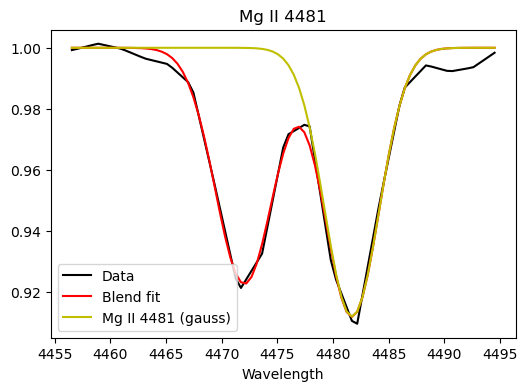

He I 4471 (gauss)
amp = -0.0774651859208668 
mu = 4472.036348328677 
sigma = 2.5889018057083657 
offset = 1.0 
chi2 = 0.0007755762002771111


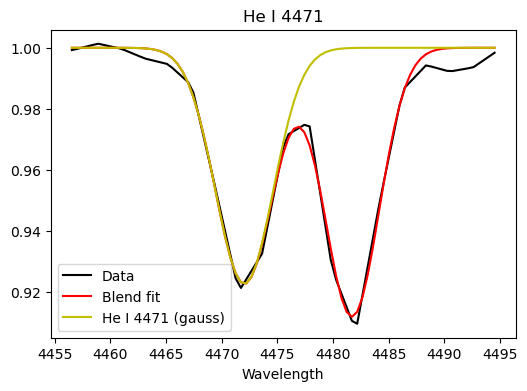

#### Mg II 4481 optimization

#### Plotting results for Mg II 4481

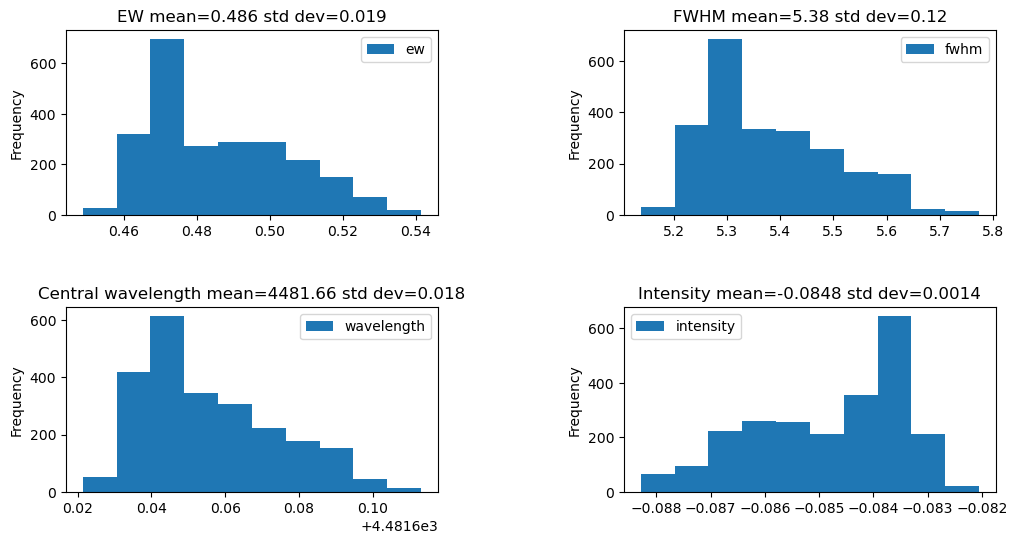

#### Plotting results for He I 4471

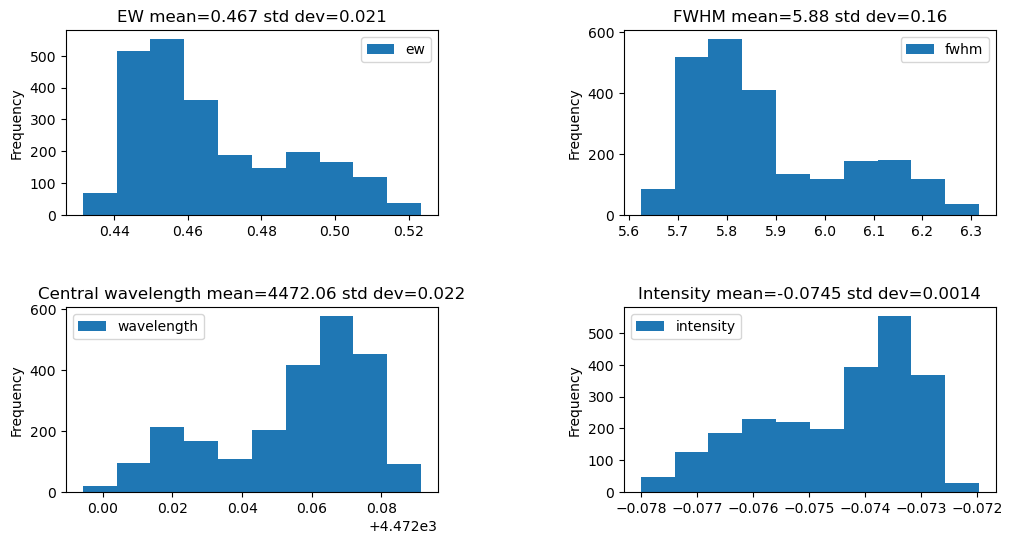

#### Mg II 4481 re-fit with best parameters

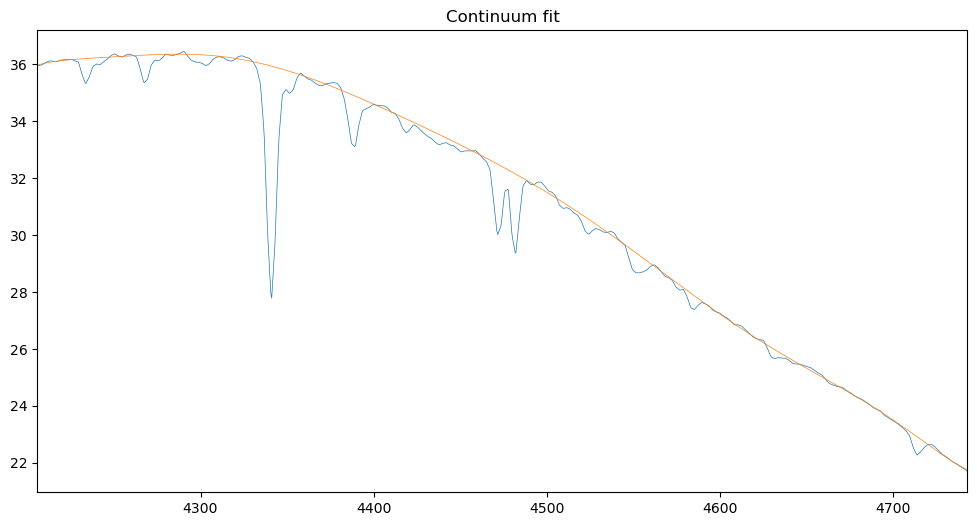

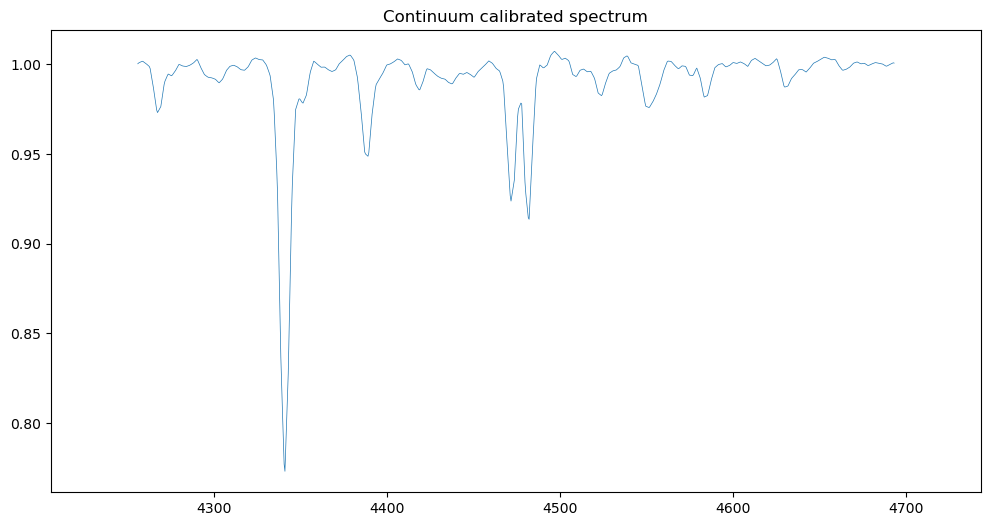

Mg II 4481 (gauss)
amp = -0.0851701317039572 
mu = 4481.656255513071 
sigma = 2.2905967507820364 
offset = 1.0 
chi2 = 0.0002524018429284041


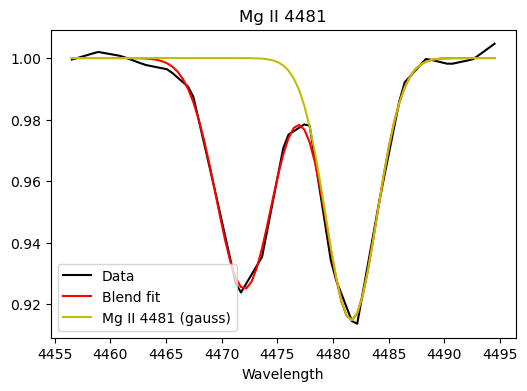

He I 4471 (gauss)
amp = -0.07499610290672162 
mu = 4472.045827051791 
sigma = 2.5259247944460315 
offset = 1.0 
chi2 = 0.0002524018429284041


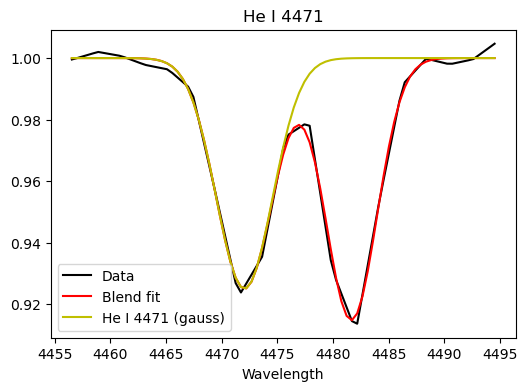

In [30]:
for measuring_blend in measuring_blends:
    results = measure_blend(wl, flux, measuring_blend, show_param_dependencies=SHOW_PARAM_DEPENDENCIES)
    summary_results = pd.concat([summary_results, results], axis=0)

## Summary Results

In [31]:
summary_results = summary_results.sort_values(by=["wavelength"], ascending=False)

summary_results


,line_name,wavelength,delta_wavelength,ew,delta_ew,fwhm,delta_fwhm,intensity,delta_intensity
7,He I 6678,6678.897199,0.026522,0.586411,0.016201,7.112958,0.163852,-0.077449,0.000604
3,Si II 6371,6372.525504,0.016861,0.424807,0.005699,5.828799,0.060993,-0.068471,0.000444
2,Si II 6347,6348.279069,0.012588,0.529501,0.006388,5.840975,0.053625,-0.085168,0.000458
6,He I 4922,4923.048468,0.009031,0.572376,0.008843,6.82229,0.072501,-0.078819,0.000396
0,H beta,4861.542108,0.006766,0.939569,0.094991,7.372604,0.00885,-0.152441,0.003157
0,Mg II 4481,4481.655889,0.018286,0.485803,0.018709,5.380157,0.12138,-0.084804,0.001383
1,He I 4471,4472.054848,0.02161,0.466591,0.021086,5.881953,0.159388,-0.074492,0.001369
5,He I 4388,4388.489385,0.081765,0.415463,0.060035,7.429406,0.809712,-0.052341,0.001929
1,Fe II 4352,4350.945853,0.72663,0.182964,0.170152,7.681804,4.783716,-0.01998,0.005089
0,H gamma,4340.976448,0.05174,1.531939,0.052585,6.662739,0.128045,-0.215962,0.003643


In [32]:
summary_results.to_csv("line_measured_rigel_20260206.csv")